# Brush GPT: a transformer that paints a cat one brush stroke at a time

**Sell Anything, notebook 8.** This notebook documents, step by step, how the cat-painting model of the game was
built and how it improved from run C to run I: where the training pictures come from, how one picture becomes about
600 brush strokes, the bug that once made every sampled painting undecodable, what each improvement changed (and
which ones did not help), how the eyes were learned, and where the data stands today.

| Section | Question |
|---|---|
| 1 | What is the whole pipeline, and what does the game actually show? |
| 2 | **Data.** How did we get nine face landmarks onto thousands of cats that had none, and which cats did we keep? |
| 3 | **Method.** How is one photo turned into an ordered list of strokes, and into tokens? When does the painter stop? |
| 4 | **The bug.** Why did 0 of 256 sampled paintings decode, and what fixed it? |
| 5 | **Results.** Runs C to I: what each change was, why, and what it did |
| 6 | How did the eyes get learned, stage by stage? How is "eye quality" measured? |
| 7 | **Where we are.** The CAT dataset paintings; what has *not* been trained yet |
| 8 | Limitations and next steps |
| 9 | Verification: where every number comes from |

**Evidence rule.** Every number in this notebook is one of three kinds, and the last section lists them all:
*computed here* from a file a run saved; *quoted* from a project document (`docs/devlog/…`, `docs/model-versions.md`)
with the document named; or **not measured**, written as such. Nothing is estimated. The notebook trains and samples
no model: it reads saved logs and metrics, and decodes and renders saved token files on the CPU (about a quarter of a
second per painting), so it opens and runs in a couple of minutes.

In [1]:
import hashlib
import json
import os
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

os.environ["BRUSHGPT_DEVICE"] = "cpu"             # nothing here may touch the GPU the painter is using
sys.path.insert(0, str(Path.cwd().parent))        # this notebook lives in ml/notebooks
from sellanything_ml.sketch import brushgpt as G       # decode / render only; no model is built
from sellanything_ml.sketch import brushtokens as T
from sellanything_ml.sketch import catbrush as B

ML = Path.cwd().parent
REPO = ML.parent
LAND = Path.home() / "Digipen fall 2026" / "cat-face-landmarks"
RUNS, TOK = ML / "runs/brushgpt", ML / "data/processed/brushgpt"
NAMES = ["C_overlap_heads", "D_all_cats", "E_points", "F_eye_weight", "G_points_eyes", "H_aligned",
         "I_aligned_points_eyes"]
SHORT = {n: n[0] for n in NAMES}
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

USED, VERIFY = [], []                             # every file read; every number with its source (section 9)


def need(path):
    path = Path(path)
    USED.append(path)
    return path


def jl(path):
    return [json.loads(line) for line in open(need(path))]


def ver(claim, value, source, kind):
    """Register a number for the verification table. kind: computed here / quoted / not measured."""
    VERIFY.append((claim, value, source, kind))
    return value


def show(path, title, box=None, figsize=(11, 4)):
    im = Image.open(need(path)).convert("RGB")
    if box:
        im = im.crop(box)
    plt.figure(figsize=figsize)
    plt.imshow(im)
    plt.axis("off")
    plt.title(title)
    plt.show()


print("torch-free pieces loaded; device forced to", os.environ["BRUSHGPT_DEVICE"])

torch-free pieces loaded; device forced to cpu


## 1. The pipeline in one page

```
CAT dataset (9,996 photos, 9 hand-placed face points each)
   └─► landmark model (MAE-pretrained ViT + ViTPose-style head)            [section 2.1]
          └─► labels for AFHQ's 5,558 cat faces (no labels of their own)   [section 2.2]
                 └─► fixed rules drop cut-off ears and uncertain faces      [section 2.3]  → 4,085 cats
                        └─► painter: photo → 608 strokes, big to small      [section 3]    → 3,046 tokens
                               └─► Brush GPT (27.9 M parameters) learns the token sequences   [sections 4, 5]
                                      └─► samples are rendered and judged (FID, eye judge)    [section 6]
```

Two choices shape everything after them. **First, a painting is a sequence.** The GPT does not predict pixels: it
writes the strokes in the order a painter would lay them, coarse strokes first. **Second, every painting has the same
layout** (the same stages, the same number of strokes per stage, five tokens per stroke), so the model always knows
which kind of token comes next. That second property is both what makes the data easy to model and what is behind the
bug in section 4.

The project rule that governs all of this (the ground rules at the top of the repository): a model may only get better through its pre-training data and
amount, its size and tokenizer, its training data, loss, hyper-parameters and training length. No rule, filter or
patch may stand in for what the model should learn. Section 4 and the limitations come back to what that means here.

### 1.1 What the game shows: the model really paints, one stroke at a time

In the Sell Anything demo, when the player opens the cat shelter, **Brush GPT paints eight new cats live, one after another**
(`ml/sellanything_ml/sketch/shelter.py`). Nothing is replayed and nothing is looked up. For each cat the model is started from the
`BOS` token and writes **one token at a time**; it first writes the nine face points (18 tokens), then the strokes. As soon as the
five tokens of a stroke are out, **that stroke is laid on the canvas on top of everything painted before it**, so the player
watches the picture grow stroke by stroke while the model is still writing. Every token is sampled at temperature 1 among the tokens its
position allows, and nothing is picked, re-ranked or filtered afterwards. The model in the game is run I (section 5).

The cell below replays one real run of exactly that code (`make_08_shelter.py` ran `ShelterPainter` on the CPU with seed 0 and saved the
eight cats' tokens and the time each took; this notebook then re-draws each cat from its tokens, stroke by stroke).

saved run of the game's shelter painter: model I_aligned_points_eyes, seed 0, device cpu, 8 cats
seconds per cat: [12.61, 12.59, 13.21, 12.27, 15.58, 15.51, 16.21, 13.3]   mean 13.9  tokens per cat: 3063
tokens per second while sampling (all 8 cats): 220
valid tokens (every token inside its position's field): True


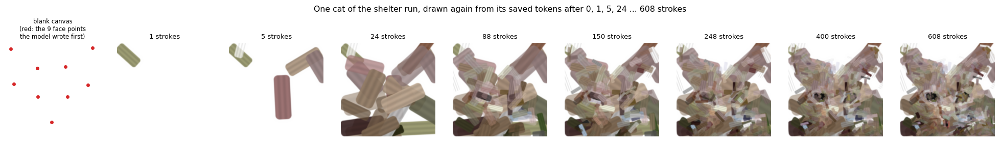

In [2]:
sh = np.load(need(Path("_src/data_08/shelter_run_I.npz")))
rows_sh = sh["tokens"]
secs = sh["seconds"]
print(f"saved run of the game's shelter painter: model {sh['run']}, seed {int(sh['seed'])}, device {sh['device']}, {len(rows_sh)} cats")
print("seconds per cat:", secs.tolist(), "  mean", round(float(secs.mean()), 1), " tokens per cat:", rows_sh.shape[1] - 1)
print("tokens per second while sampling (all 8 cats):", round(float((rows_sh.shape[1] - 1) * len(secs) / secs.sum())))
print("valid tokens (every token inside its position's field):", bool(G.valid(rows_sh).all()))
ver("shelter painter, run I on the CPU: seconds per cat (mean) / cats", (round(float(secs.mean()), 1), len(secs)), "_src/data_08/shelter_run_I.npz (make_08_shelter.py)", "computed here")


def first_n_strokes(stages, n):
    """The stages' strokes up to the first n strokes in painting order (what is on the canvas after n strokes)."""
    out, left = [], n
    for st in stages:
        take = min(left, len(st["alpha"]))
        if take:
            out.append({k: v[:take] for k, v in st.items()})
        left -= take
        if left <= 0:
            break
    return out


def render_n(row, n):
    if n == 0:
        return np.ones((B.SIDE, B.SIDE, 3))
    return T.render(first_n_strokes(T.decode(G.strokes_only(row).tolist()), n)).clip(0, 1)


counts = [0, 1, 5, 24, 88, 150, 248, 400, 608]            # 24 = end of stage 1, 88 = stage 2, 248 = stage 3, 608 = all
cat = 3
pts = (rows_sh[cat, 1:1 + G.PREFIX].reshape(-1, 2) - np.array([T.OFFSET["x"], T.OFFSET["y"]]) + 0.5)
fig, ax = plt.subplots(1, len(counts), figsize=(2.1 * len(counts), 2.5))
for a, n in zip(ax, counts):
    a.imshow(render_n(rows_sh[cat], n))
    a.set_title(f"{n} strokes", fontsize=9)
    a.axis("off")
ax[0].scatter(pts[:, 0], pts[:, 1], c="tab:red", s=14)
ax[0].set_title("blank canvas\n(red: the 9 face points\nthe model wrote first)", fontsize=8)
plt.suptitle("One cat of the shelter run, drawn again from its saved tokens after 0, 1, 5, 24 ... 608 strokes", y=1.04)
plt.tight_layout()
plt.show()

eye judge on these 8 finished cats: mean 0.4828 +- 0.0214 (n = 8; run I's 128-sample evaluation: 0.488 +- 0.006); per cat [0.4265, 0.5273, 0.3621, 0.5222, 0.4562, 0.5196, 0.5604, 0.4879]


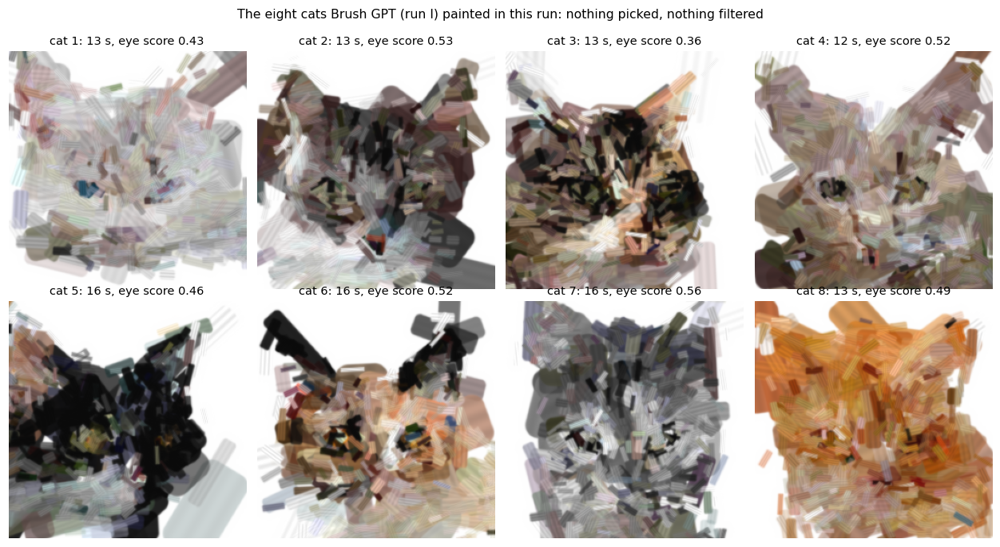

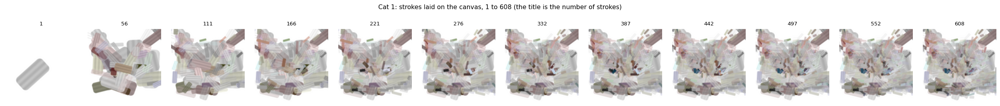

In [3]:
# all eight cats of the run, finished, with the seconds each took on the CPU and the eye judge's score
se_ = json.loads(need(Path("_src/data_08/shelter_eye.json")).read_text())
fig, ax = plt.subplots(2, 4, figsize=(12, 6.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(render_n(rows_sh[i], 608))
    a.set_title(f"cat {i + 1}: {secs[i]:.0f} s, eye score {se_['per_cat_eye_score'][i]:.2f}", fontsize=10)
    a.axis("off")
plt.suptitle("The eight cats Brush GPT (run I) painted in this run: nothing picked, nothing filtered", y=1.0)
print(f"eye judge on these 8 finished cats: mean {se_['mean']} +- {se_['se']} (n = 8; run I's 128-sample evaluation: 0.488 +- 0.006);",
      "per cat", se_["per_cat_eye_score"])
ver("shelter run (8 cats, run I, CPU, seed 0): eye score mean +- SE", (se_["mean"], se_["se"]), "_src/data_08/shelter_eye.json (make_08_shelter_eye.py)", "computed here")
plt.tight_layout()
plt.show()

# the build-up as a strip of 24 equally spaced steps for one cat, to see that it is the same painting growing
steps = np.linspace(1, 608, 12).astype(int)
fig, ax = plt.subplots(1, 12, figsize=(24, 2.3))
for a, n in zip(ax, steps):
    a.imshow(render_n(rows_sh[0], n))
    a.set_title(f"{n}", fontsize=9)
    a.axis("off")
plt.suptitle("Cat 1: strokes laid on the canvas, 1 to 608 (the title is the number of strokes)", y=1.08)
plt.tight_layout()
plt.show()

Each frame is the *same* painting with more strokes on top: the first 24 strokes are broad blocks of colour (stage 1), strokes 25 to 88 shape
the head and ears (stage 2), strokes 89 to 248 typically add the eyes, nose and stripes (stage 3) and the last 360 strokes are detail (stage 4). The model decides every
stroke itself: the order is the painter's coarse-to-fine order it learned from the training data, and a stroke, once laid, is never changed (it can only
be covered by later ones). On the CPU the model writes a whole cat in the time shown in each panel's title, 12 to 16 seconds in this run, so the game can paint
all eight cats while the shelter screen is open. These eight cats were *not* selected: they are the first run with seed 0. They are also not all good, and the notebook shows it: cat 1 is a diffuse mass with no readable face, and the eye judge scores the eight cats from 0.36 to 0.56 (mean 0.483 ± 0.021 over only 8 cats, consistent with the 0.488 ± 0.006 that run I gets on 128 samples, section 5). The judge is a proxy (section 6) and does not always agree with a person looking at the picture; it is printed next to the pictures so that the quality is read as it is, not as the best case.

This also states the thing the rest of the notebook has to be read against: **Brush GPT is not an image generator that is shown strokes afterwards.** Its
output *is* the stroke list. That is why the training data are stroke lists (section 3), why the quality of the strokes in the first stages
decides what the final face looks like (section 6), and why the token-level bug of section 4 stopped everything: if one token is in the wrong
field, the stroke it belongs to cannot be drawn.

## 2. Data: labelling cats that had no labels

### 2.1 The landmark model (separate repository `cat-face-landmarks`)

The CAT dataset (Zhang et al., 2008) has nine hand-placed points per cat (both eyes, the mouth, three on each ear) but
small, loosely framed faces. AFHQ has large, sharp, consistently framed faces and no points. We want the points on
AFHQ, because every later step (aligning faces, weighting the eyes, judging eyes) needs them. So we built a landmark
finder in its own repository, <https://github.com/alina0607/cat-face-landmarks>:

* **Pre-training, no labels.** A ViT-Small encoder (patch 16, 224 px, width 384, 12 layers) is trained as a *masked
  autoencoder*: three quarters of the patches are hidden and it reconstructs them. The 13,061 faces used include the
  unlabeled AFHQ cats the model will later be applied to.
* **Fine-tuning with a few labels.** A ViTPose-style decoder turns patch features into one heat map per landmark; a
  soft-argmax (integral regression) gives each point's position. Trained on the CAT dataset's 7,996 labelled training faces
  (1,000 validation, 1,000 test), 100 epochs.
* **Software and hardware.** PyTorch; the masked-autoencoder run on this Mac's GPU (about 100 s an epoch, 300 epochs); the
  two fine-tuning runs on a Kaggle Tesla T4 with identical settings, only the starting weights differing.

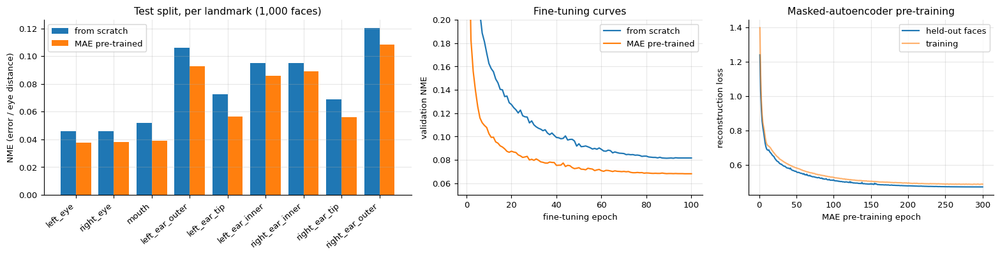

{'pose_scratch': (0.078, 0.214), 'pose_mae': (0.067, 0.122)}
best validation NME: {'pose_scratch': 0.0814, 'pose_mae': 0.0681}
MAE held-out loss, epoch 1 -> 300: 1.2407 -> 0.4723


In [4]:
res = {n: json.loads(need(LAND / f"runs/{n}/eval_test.json").read_text()) for n in ("pose_scratch", "pose_mae")}
lm = list(res["pose_mae"]["nme_per_landmark"])
curves = {n: jl(LAND / f"runs/{n}/metrics.jsonl") for n in ("pose_scratch", "pose_mae")}
mae = jl(LAND / "runs/mae/metrics.jsonl")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1.5, 1, 1]})
x, w = np.arange(9), 0.4
ax[0].bar(x - w / 2, [res["pose_scratch"]["nme_per_landmark"][k] for k in lm], w, label="from scratch")
ax[0].bar(x + w / 2, [res["pose_mae"]["nme_per_landmark"][k] for k in lm], w, label="MAE pre-trained")
ax[0].set_xticks(x)
ax[0].set_xticklabels(lm, rotation=40, ha="right")
ax[0].set(ylabel="NME (error / eye distance)", title="Test split, per landmark (1,000 faces)")
ax[0].legend()
for n, lab in (("pose_scratch", "from scratch"), ("pose_mae", "MAE pre-trained")):
    ax[1].plot([r["epoch"] for r in curves[n]], [r["val_nme"] for r in curves[n]], label=lab)
ax[1].set(ylim=(0.05, 0.2), xlabel="fine-tuning epoch", ylabel="validation NME", title="Fine-tuning curves")
ax[1].legend()
ax[2].plot([r["epoch"] for r in mae], [r["held_out"] for r in mae], label="held-out faces")
ax[2].plot([r["epoch"] for r in mae], [r["loss"] for r in mae], label="training", alpha=0.6)
ax[2].set(xlabel="MAE pre-training epoch", ylabel="reconstruction loss", title="Masked-autoencoder pre-training")
ax[2].legend()
plt.tight_layout()
plt.show()

for n in res:
    r = res[n]
    ver(f"landmark model {n}: test NME / failure rate (NME>0.1)", (r["nme"], r["failure_rate_0.1"]),
        f"cat-face-landmarks/runs/{n}/eval_test.json", "computed here")
ver("MAE held-out loss, epoch 1 -> 300", (mae[0]["held_out"], mae[-1]["held_out"]),
    "cat-face-landmarks/runs/mae/metrics.jsonl", "computed here")
print({n: (res[n]["nme"], res[n]["failure_rate_0.1"]) for n in res})
print("best validation NME:", {n: min(r["val_nme"] for r in c) for n, c in curves.items()})
print("MAE held-out loss, epoch 1 -> 300:", mae[0]["held_out"], "->", mae[-1]["held_out"])

The pre-trained start lowers the test error from 0.0780 to 0.0670 (normalised mean error: the distance to the true
point divided by the distance between the eyes) and the failure rate (error above 0.1) from 21.4% to 12.2%. The left
panel shows where: every landmark improves, the eyes (0.046 to 0.038) and the mouth (0.052 to 0.039) most clearly. The
middle panel shows that the pre-trained run passes the from-scratch run's *best* error long before epoch 100, and the
right panel that the masked-autoencoder's held-out loss fell from 1.24 to 0.47 over 300 epochs. The ear bases stay
the hardest points (0.09 to 0.11), which fits the suspicion that their hand labels are themselves noisy.

One prediction of ours was wrong, and the project log says so: before the run we expected the largest gain on the ear
bases (no edge of their own to find). The opposite happened: sharp points gained most (devlog 2026-10-10 §1).

These two numbers matter for the rest of the notebook only in one way: the eyes are the points the model finds best
(NME about 0.038), which is why its *eye confidence* can later serve as an independent judge of painted eyes
(section 6).

### 2.2 Labelling AFHQ, and one fix

AFHQ's crops are tight: the face fills the 512 × 512 frame, tighter than anything the model saw in training, and a
soft-argmax can never place a point outside its input. The first labels (from the from-scratch model) put many ear
tips in the image corners. The fix, `label run --pad 1.5` (cat-face-landmarks commit `d6e00d0`), shrinks each image into
the middle of a grey frame so the face covers 1/1.5 of the input as it did in training, and maps the predictions back
to the photo's own pixels, outside it if need be. The tool was first tested with a fake model that puts every point on
the input's corners; the results matched the hand calculation. All 5,558 AFHQ cats were then labelled with the
MAE-pretrained model at pad 1.5.

AFHQ cats labelled: 5558
ear tip outside the image by more than (eye distances) -> share of cats
      0:  36.5%  (2029 cats)
   0.05:  28.8%  (1599 cats)
    0.1:  22.4%  (1245 cats)
    0.2:  14.2%  (790 cats)
    0.3:   8.3%  (459 cats)


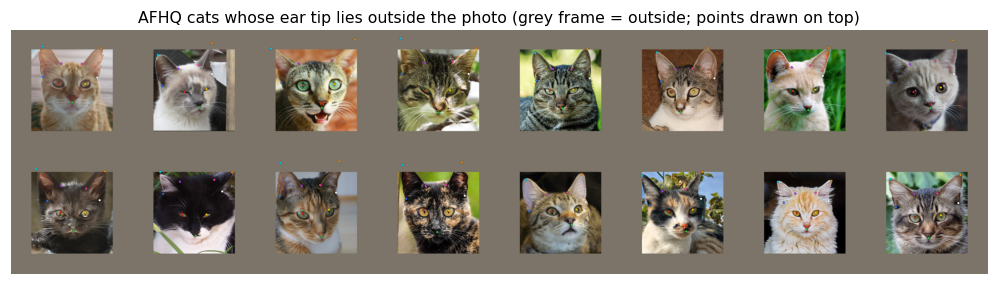

In [5]:
chk = np.load(need(ML / "data/processed/afhq_cats_mae_pad1.5_checks.npz"))
lab = np.load(need(ML / "data/processed/afhq_cats_mae_pad1.5.npz"))
tip = chk["tip_outside"]                                    # how far the worst ear tip lies outside, in eye distances
rows = [(t, float((tip > t).mean())) for t in (0, 0.05, 0.1, 0.2, 0.3)]
print("AFHQ cats labelled:", len(lab["ids"]))
print("ear tip outside the image by more than (eye distances) -> share of cats")
for t, s in rows:
    print(f"   {t:>4}: {s:6.1%}  ({int((tip > t).sum())} cats)")
ver("AFHQ cats labelled (MAE, pad 1.5)", len(lab["ids"]), "ml/data/processed/afhq_cats_mae_pad1.5.npz", "computed here")
ver("cats with an ear tip outside the image (>0 / >0.1 eye distances)", (round(rows[0][1], 3), round(rows[2][1], 3)),
    "ml/data/processed/afhq_cats_mae_pad1.5_checks.npz", "computed here")
show(LAND / "runs/afhq_tips_outside.png", "AFHQ cats whose ear tip lies outside the photo (grey frame = outside; points drawn on top)",
     figsize=(12, 3.2))

36.5% of the cats have at least one ear tip outside the image, 22.4% by more than 0.1 eye distance. Looking at them
(the figure draws the photo on a padded canvas) confirms that these tips belong to ears the crop really cuts off at
the top. This is the first of two reasons to filter the data in 2.3.

### 2.3 Which cats we keep: two fixed rules

The generator's *training* pictures are filtered by objective rules (outputs of the generator are never filtered). The
rules were measured first and shown to the project owner before use. "Unsure landmarks" needs a signal that tracks the
real error, so each candidate signal was first scored on the CAT validation set, where the truth is known (MAE model,
1,000 faces, "failure" = NME above 0.1; values quoted from devlog 2026-10-10 §3):

| signal | AUROC for failure | note |
|---|---|---|
| mean heat-map peak ("confidence") | 0.567 | barely better than chance |
| lowest heat-map peak | 0.606 | |
| peak on eyes and mouth | 0.471 | worse than chance |
| **mirror disagreement** | **0.825** | correlation 0.661 with the error |

*Mirror disagreement*: predict the face and its mirror image, swap left and right back, and average the distance
between the two predictions over the eye distance. The model's own confidence did not track its errors; its
disagreement with itself did. The two rules, as approved after looking at example rows (`ml/runs/generator_filter_rules.png`):

* **Rule A**: an ear tip more than 0.1 eye distance outside the image: the ear is cut off.
* **Rule B**: mirror disagreement in the top 5% (ear tips excluded, since a cut-off tip is a guess either way). The
  owner first saw a 10% threshold and judged it too loose, because the cats just past it were mostly ordinary frontal cats.

rule A drops 1245, rule B drops 278, both 50; kept 4085 of 5558 (73.5%);  mirror threshold (95th pct) = 0.0633
mirror disagreement median / 90th / 95th: [0.0325, 0.0537, 0.0633]


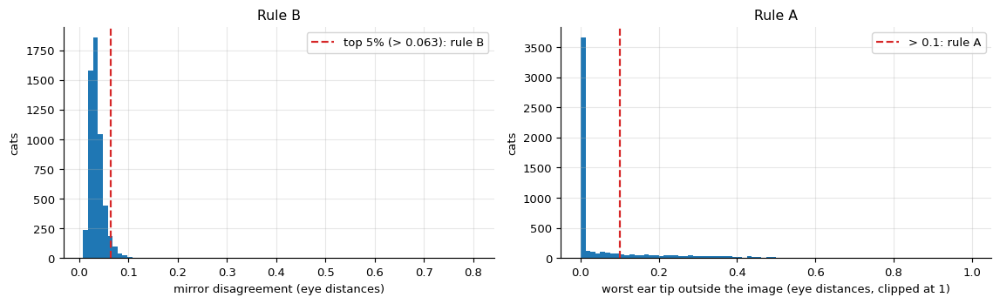

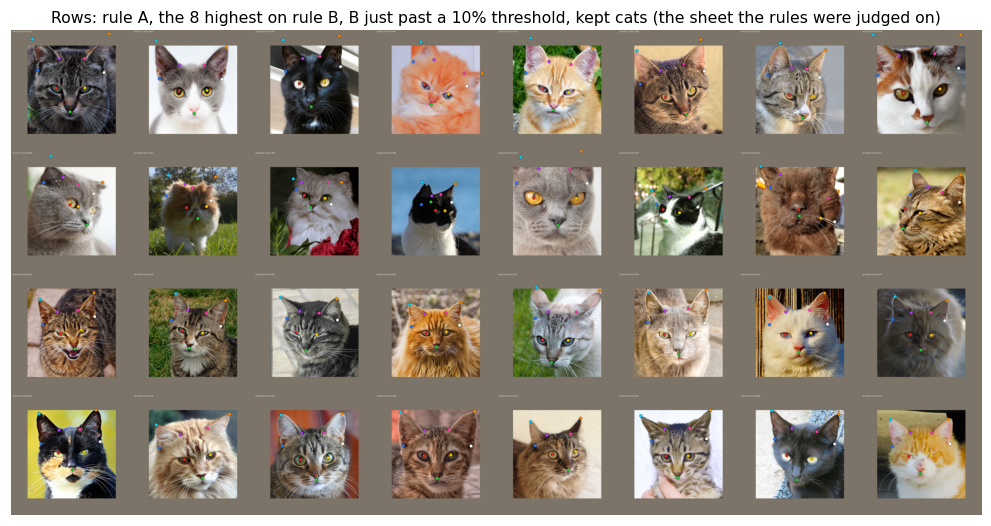

tokens file used by runs D-G: paintings 4085 {'train': 3413, 'test': 380, 'val': 292}


(3413, 292, 380)

In [6]:
mirror = np.delete(chk["mirror"], [4, 7], axis=1).mean(1)          # as tools/paint_afhq.py: ear tips left out
thr = float(np.quantile(mirror, 0.95))
A, Bm = tip > 0.1, mirror > thr
kept = ~A & ~Bm
print(f"rule A drops {int(A.sum())}, rule B drops {int(Bm.sum())}, both {int((A & Bm).sum())}; "
      f"kept {int(kept.sum())} of {len(kept)} ({kept.mean():.1%});  mirror threshold (95th pct) = {thr:.4f}")
print("mirror disagreement median / 90th / 95th:", [round(float(np.quantile(mirror, q)), 4) for q in (0.5, 0.9, 0.95)])
ver("rule A / rule B / both / kept (AFHQ, 5,558 cats)", (int(A.sum()), int(Bm.sum()), int((A & Bm).sum()), int(kept.sum())),
    "ml/data/processed/afhq_cats_mae_pad1.5_checks.npz (same formula as tools/paint_afhq.py)", "computed here")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(mirror, bins=80, color="tab:blue")
ax[0].axvline(thr, color="tab:red", ls="--", label=f"top 5% (> {thr:.3f}): rule B")
ax[0].set(xlabel="mirror disagreement (eye distances)", ylabel="cats", title="Rule B")
ax[0].legend()
ax[1].hist(np.clip(tip, -0.2, 1.0), bins=80, color="tab:blue")
ax[1].axvline(0.1, color="tab:red", ls="--", label="> 0.1: rule A")
ax[1].set(xlabel="worst ear tip outside the image (eye distances, clipped at 1)", ylabel="cats", title="Rule A")
ax[1].legend()
plt.tight_layout()
plt.show()
show(ML / "runs/generator_filter_rules.png", "Rows: rule A, the 8 highest on rule B, B just past a 10% threshold, kept cats (the sheet the rules were judged on)",
     figsize=(12, 6))

z = np.load(need(TOK / "tokens_runs_DEFG.npz"))
split = Counter(z["split"].tolist())
print("tokens file used by runs D-G: paintings", len(z["ids"]), dict(split))
ver("paintings in tokens_runs_DEFG.npz, train / val / test", (split["train"], split["val"], split["test"]),
    "ml/data/processed/brushgpt/tokens_runs_DEFG.npz", "computed here")

The rules drop 1,245 cats (A) and 278 (B), 50 of them by both, and keep **4,085 of 5,558 (73.5%)**. All 4,085 were
painted (3,413 for training, 292 validation, 380 test; the split is by a hash of the file name, so painting more cats
never moves a cat between splits, and AFHQ's own test folder is the test set). The histograms show that B's threshold
(0.063) sits in the tail rather than cutting the bulk, and that A removes a long tail of cut-off ears.

**What is *not* measured here.** AFHQ has no labels, so how well the landmark model transfers to it can only be
measured against hand labels. A browser tool for that exists in the landmark repository (`handlabel`, 50 AFHQ test
cats), but no score file is saved in either repository, so this notebook reports **no hand-label transfer score**.
The evidence that the AFHQ labels are usable is therefore indirect: the CAT-test numbers above, and the fact that the
eye-judge built on the same model finds the eyes of real paintings with confidence about 0.5 (section 6).

## 3. Method: from a photo to 608 strokes to 3,046 tokens

### 3.1 The painter

Each kept cat is cut to a square around its face (the landmarks' bounding box plus 20%, cut from the 512-pixel
original), put on white paper using a subject mask (Apple Vision's subject-lift run on the Neural Engine; 0 failures on
the 5,558 AFHQ cats), and painted by `ml/sellanything_ml/sketch/catbrush.py`. The method is *direct optimisation through
a differentiable renderer*, in the manner of Stylized Neural Painting (Zou et al., CVPR 2021), with the straight oil
stroke of Paint Transformer (Liu et al., ICCV 2021) and the coarse-to-fine idea of Learning to Paint (Huang et al.,
ICCV 2019). One stroke is a rounded rectangle (centre, length, width, angle, colour, opacity) with faint bristle streaks;
strokes are laid one over another, later on top. The painter works in stages, big strokes first:

1. **Place.** The stage's strokes are put down with probability proportional to how far the canvas still is from the
   photo (so effort goes where the picture is still wrong), turned along the fur's local direction (from the image's
   structure tensor) and given the photo's colour at that spot.
2. **Optimise.** Every parameter of that stage's strokes is adjusted by Adam (lr 0.05, **150 steps** per stage) to minimise the
   L1 distance between canvas and photo; earlier stages stay fixed.
3. **Snap.** The finished stage's parameters are moved onto the token grid before the next stage starts, so the later,
   smaller strokes paint over the snapping error and the final picture is exactly what the tokens say.

In [7]:
rows = []
for k, (length, width, n) in enumerate(B.STAGES):
    rows.append({"stage": k + 1, "brush length x width (px on 256)": f"{length} x {width}", "strokes": n,
                 "tokens (5 per stroke + marker)": 5 * n + 1, "used for Brush GPT": "yes" if k < G.STAGES else "no"})
df = pd.DataFrame(rows)
display(df.set_index("stage"))
used = sum(r["strokes"] for r in rows[:G.STAGES])
print("strokes in the 4 used stages:", used, " tokens per painting (BOS + 4 markers + 5 x strokes + EOS):", G.SEQ)
ver("strokes per painting / tokens per painting", (used, G.SEQ), "ml/sellanything_ml/sketch/catbrush.py STAGES, brushgpt.py SEQ", "computed here")

f = pd.DataFrame([{"field": name, "tokens": n, "first id": T.OFFSET[name], "share of vocabulary": f"{n / T.VOCAB:.1%}"}
                  for name, n in T.FIELDS.items()])
display(f.set_index("field"))
print("vocabulary:", T.VOCAB, "= 1 BOS + 1 EOS + 5 stage markers (ids 0-6) + the five fields")
ver("vocabulary size", T.VOCAB, "ml/sellanything_ml/sketch/brushtokens.py", "computed here")

,brush length x width (px on 256),strokes,tokens (5 per stroke + marker),used for Brush GPT
stage,,,,
1,96 x 40,24,121,yes
2,56 x 22,64,321,yes
3,32 x 12,160,801,yes
4,18 x 7,360,1801,yes
5,10 x 4,600,3001,no


strokes in the 4 used stages: 608  tokens per painting (BOS + 4 markers + 5 x strokes + EOS): 3046


,tokens,first id,share of vocabulary
field,,,
x,256,7,3.4%
y,256,263,3.4%
angle,32,519,0.4%
size,36,551,0.5%
paint,6912,587,92.2%


vocabulary: 7499 = 1 BOS + 1 EOS + 5 stage markers (ids 0-6) + the five fields


7499

A stroke is **five tokens**: `x` and `y` (1-pixel bins on the 256-pixel canvas, 256 values each), `angle` (32 bins over
[0, π), since the brush is symmetric end to end), `size` (length and width, 6 levels each within 0.5 to 1.5 times the
stage's brush, as one of 36 tokens) and `paint` (12 levels per colour channel and 4 opacity levels, one of 6,912
tokens). A painting is `BOS, STAGE₁, 24 strokes, STAGE₂, 64 strokes, STAGE₃, 160 strokes, STAGE₄, 360 strokes, EOS`:
**608 strokes, 3,046 tokens**, always. The vocabulary is 7,499 (an earlier hand-off note said 7,531; 7,499 is what the code
gives, and devlog 2026-10-11 records the correction). Colour is the largest field by far, 92% of the vocabulary, and it
is also the field the model finds hardest (section 5).

Brush size is not spelled out: the stage marker carries it. Before the GPT sees anything, the stages are listed in the
fixed order big to small, so the first 24 strokes are broad blocks of colour and the last 360 are the 18 × 7 px
detail strokes (the strokes' sizes are in the table above).

### How many strokes one cat takes, and how many guesses the model makes

Every cat is painted in the same **608 strokes**, in four stages from coarse to fine:

| stage | strokes | strokes no. | what they paint (section 1.1) |
|---|---|---|---|
| 1 | 24 | 1–24 | broad blocks of colour: the coat and the rough head |
| 2 | 64 | 25–88 | the head and ears |
| 3 | 160 | 89–248 | usually where the eyes, nose and stripes first appear |
| 4 | 360 | 249–608 | detail |
| total | **608** | | |

Runs E, G and I (and the runs after them) also write the cat's nine face points first, as 18 x/y tokens after `BOS`.
For them a painting is 1 `BOS` + 18 point tokens + 4 stage markers + 608 × 5 stroke tokens + 1 `EOS` = **3,064 tokens**
(3,046 without the points), so painting one cat means predicting the next token **3,063 times**, one after another (the
next cell computes both numbers from the code). Because each stage is snapped to the token grid before the next one is
painted, the tokens are exactly the strokes the painter laid down. Section 6.3 measures, stage by stage, where the
generated paintings lose the eyes: mostly in the two finest stages (160 + 360 strokes).

In [8]:
with_points = G.SEQ + G.PREFIX
print("strokes per painting:", sum(G.STROKES), " tokens without face points:", G.SEQ, " with face points:", with_points,
      " next-token predictions per painting:", with_points - 1)
ver("tokens per painting with face points / predictions per painting", (with_points, with_points - 1),
    "ml/sellanything_ml/sketch/brushgpt.py SEQ, PREFIX", "computed here")

strokes per painting: 608  tokens without face points: 3046  with face points: 3064  next-token predictions per painting: 3063


(3064, 3063)

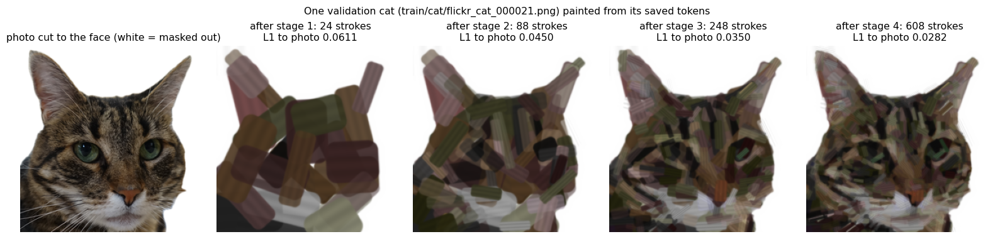

first stroke of stage 1, as written in the token file (positions 2-6):


,token id,id within field,meaning (bin centre)
field,,,
x,179,172,172.5 px
y,418,155,155.5 px
angle,530,11,64.7 deg
size,572,21,104.0 x 43.3 px
paint,1794,1207,"rgb [0.21, 0.12, 0.12], opacity 0.91"


[0.0611, 0.045, 0.035, 0.0282]

In [9]:
val_ids = np.flatnonzero(z["split"] == "val")
demo = int(val_ids[0])
rel = str(z["ids"][demo])
stem = Path(rel).stem
meta = np.load(need(ML / f"data/processed/afhq_brush_face/{stem}.npz"))
box = tuple(int(v) for v in meta["box"])
photo = B.load(str(need(ML / "data/raw/afhq" / rel)), str(need(ML / f"data/processed/afhq_masks/{stem}_mask1.png")), box)
target = photo.target.numpy()
stages = T.decode(z["tokens"][demo].tolist())
frames = [T.render(stages[:k]) for k in range(1, 5)]
l1s = [float(np.abs(f - target).mean()) for f in frames]

fig, ax = plt.subplots(1, 5, figsize=(15, 3.6))
ax[0].imshow(target)
ax[0].set_title("photo cut to the face (white = masked out)")
for k in range(4):
    ax[k + 1].imshow(frames[k].clip(0, 1))
    ax[k + 1].set_title(f"after stage {k + 1}: {sum(len(s['alpha']) for s in stages[:k + 1])} strokes\nL1 to photo {l1s[k]:.4f}")
for a in ax:
    a.axis("off")
plt.suptitle(f"One validation cat ({rel}) painted from its saved tokens", y=1.02)
plt.tight_layout()
plt.show()

row = z["tokens"][demo]
print("first stroke of stage 1, as written in the token file (positions 2-6):")
first = row[2:7]
names = ["x", "y", "angle", "size", "paint"]
p = T.stroke_params(first[None], 0)
vals = [f"{p['xy'][0, 0]:.1f} px", f"{p['xy'][0, 1]:.1f} px", f"{np.degrees(p['angle'][0]):.1f} deg",
        f"{p['length_width'][0, 0]:.1f} x {p['length_width'][0, 1]:.1f} px",
        f"rgb {np.round(p['colour'][0], 2).tolist()}, opacity {p['alpha'][0]:.2f}"]
display(pd.DataFrame({"field": names, "token id": first.tolist(), "id within field": [int(t - T.OFFSET[n]) for t, n in zip(first, names)],
                      "meaning (bin centre)": vals}).set_index("field"))
ver("demo cat L1 to photo after stages 1-4", [round(v, 4) for v in l1s], "ml/data/processed/brushgpt/tokens_runs_DEFG.npz + AFHQ photo", "computed here")

The demonstration cat is a *validation* cat, so none of the models in section 5 trained on it. Each stage is a
visible step: blocks of colour; the head and ears; eyes and stripes; detail. The error against the photo falls with every
stage. The table shows what a stroke looks like in tokens: five integers, each the index of a bin whose centre is the value
in the last column. Decoding goes the other way: the integers give back bin centres, and the renderer paints them.

In [10]:
# 20 validation cats: error after each stage; and does the token file reproduce the painter's own logged L1?
log = {Path(r["id"]).stem: r for r in jl(ML / "data/processed/afhq_brush_face/log.jsonl")}
per_stage, check = [], []
for i in val_ids[:20]:
    rel_i = str(z["ids"][i])
    s_i = Path(rel_i).stem
    bx = tuple(int(v) for v in np.load(ML / f"data/processed/afhq_brush_face/{s_i}.npz")["box"])
    tgt = B.load(str(ML / "data/raw/afhq" / rel_i), str(ML / f"data/processed/afhq_masks/{s_i}_mask1.png"), bx).target.numpy()
    st = T.decode(z["tokens"][i].tolist())
    ls = [float(np.abs(T.render(st[:k]) - tgt).mean()) for k in range(1, 5)]
    per_stage.append(ls)
    if s_i in log:
        check.append((log[s_i]["l1"], ls[-1]))
per_stage = np.array(per_stage)
print("mean L1 to the photo after stage 1..4 over", len(per_stage), "validation cats:", per_stage.mean(0).round(4).tolist())
print("std over cats:", per_stage.std(0).round(4).tolist())
d = np.abs(np.array(check)[:, 0] - np.array(check)[:, 1])
print(f"painter's logged L1 vs L1 of the picture rebuilt from tokens, {len(check)} cats with a log line: max difference {d.max():.5f} (log has 4 decimals)")
rt = [T.encode(T.decode(z["tokens"][i].tolist())) == z["tokens"][i].tolist() for i in range(0, len(z["tokens"]), 20)]
print(f"decode -> encode returns the same tokens for {sum(rt)} of {len(rt)} paintings tried (every 20th of {len(z['tokens'])})")
ver("mean L1 after stages 1-4 (20 validation cats)", per_stage.mean(0).round(4).tolist(), "tokens_runs_DEFG.npz + AFHQ photos", "computed here")
ver("token round trip exact (decode -> encode)", f"{sum(rt)}/{len(rt)}", "tokens_runs_DEFG.npz", "computed here")
ver("logged painter L1 vs rebuilt-from-tokens L1, max abs difference", round(float(d.max()), 5), "afhq_brush_face/log.jsonl", "computed here")

mean L1 to the photo after stage 1..4 over 20 validation cats: [0.0642, 0.0471, 0.0359, 0.0287]
std over cats: [0.0111, 0.0099, 0.0084, 0.0064]
painter's logged L1 vs L1 of the picture rebuilt from tokens, 20 cats with a log line: max difference 0.00005 (log has 4 decimals)


decode -> encode returns the same tokens for 205 of 205 paintings tried (every 20th of 4085)


5e-05

Two checks matter for everything after this point. (1) The token file reproduces the painter's own logged error to the
4 decimals the log keeps: nothing is lost when a stage is snapped to the grid and written as tokens. (2) Decoding then
encoding gives back the identical token sequence for every painting tried. **The conversion between tokens and pictures is
therefore exact in both directions**; this will matter in section 4, where the failure turns out to be somewhere else.

The error figures here (about 0.03 after four stages) are for the validation cats, whose photos the painter had never
been tuned to; the eight cats of the very first stage-by-stage test (devlog 2026-10-10 §4) had 0.0814, 0.0609, 0.0479
and 0.0386, on different and in part easier-framed cats, so the two sets of numbers are not meant to match.

### 3.2 When does the painter stop? What does it cost to keep going?

There are two separate "stop" decisions, and neither is a convergence test.

* **Within a stage: a fixed 150 Adam steps.** There is no error threshold; the number is a constant of the painter
  (`catbrush.ITERS`).
* **How many stages: a token budget, decided by the project owner from the table below.** The painter's fifth stage
  (600 strokes of 10 × 4 px) was measured against the first four on 60 painted cats (devlog 2026-10-10 §4):

| stages | strokes | tokens | L1, whole canvas | L1, inside the landmark box |
|---|---|---|---|---|
| 1–3 | 248 | 1,245 | 0.0376 | 0.0464 |
| 1–4 | 608 | 3,046 | 0.0303 | 0.0369 |
| 1–5 | 1,208 | 6,047 | 0.0263 | 0.0318 |

Stage 5 doubles the tokens (3,046 to 6,047) and gains 0.0040 of L1. A GPT sequence twice as long is four times the
attention cost and much harder to learn from a few thousand cats, so painting stops after stage 4. The first version
painted the whole 512-pixel frame; it was replaced by the face-only square because the faces then fill the canvas with
real detail (devlog 2026-10-10 §4: the saving came from dropping stage 5, not from the crop, since AFHQ is framed on the face already).

**Snapping costs a little.** On the first test cat (devlog 2026-10-09), the unquantised five-stage painting reached
L1 **0.0229**; with each stage snapped to the token bins before the next, **0.0256**. Quantising one field at a time
showed where the loss comes from: position at 2 px +0.0028, colour at 8 levels +0.0029, size +0.0015, angle +0.0007,
opacity +0.0004 (all fields together 0.0307). We therefore chose 1-pixel positions and 12 colour levels, and let later
strokes absorb the rest. Those numbers are quoted from the devlog (one cat); this notebook does not re-run the painter.

In [11]:
ver("L1 stages 1-3 / 1-4 / 1-5 (60 cats), tokens 1,245 / 3,046 / 6,047", (0.0376, 0.0303, 0.0263), "docs/devlog/2026-10-10.md §4", "quoted")
ver("L1 after stage 5: continuous vs snapped to tokens (one cat)", (0.0229, 0.0256), "docs/devlog/2026-10-09.md (Brush strokes)", "quoted")
ver("quantising one field at a time, L1 increase (position 2 px, colour 8 levels)", (0.0028, 0.0029), "docs/devlog/2026-10-09.md", "quoted")
print("stage 5 would add", 6047 - 3046, "tokens (", round(6047 / 3046, 2), "x ) for an L1 gain of", round(0.0303 - 0.0263, 4))
ver("stage 5 token cost / L1 gain", (6047 - 3046, round(0.0303 - 0.0263, 4)), "derived from the quoted table", "computed here")

stage 5 would add 3001 tokens ( 1.99 x ) for an L1 gain of 0.004


(3001, 0.004)

### 3.3 The order of strokes inside a stage

The painter fits a whole stage's strokes at once, so their order in the list is simply the order its random starting
points were drawn: noise. The trial run showed what that costs: the *x* position of the next stroke was learned not at all
(loss 5.53 against ln 256 = 5.55 for guessing), while the stage markers were learned perfectly (0.003) (devlog
2026-10-11 §2). But order is not free to change: where two strokes overlap, the later one covers the earlier one, so the
order is part of the picture. The fix, **overlap order**, keeps the order of every pair of overlapping strokes (a
topological sort) and places all the others top to bottom in 32-pixel bands, left to right. Strokes that do not
overlap commute, so the picture does not change. Below we check that on real paintings and measure how far apart
consecutive strokes become.

In [12]:
def jumps(row):
    """Mean distance between the centres of consecutive strokes, per stage."""
    return [float(np.hypot(*np.diff(s["xy"], axis=0).T).mean()) for s in T.decode(row.tolist())]


sel = np.flatnonzero(z["split"] == "train")[:6]
j_list = np.array([jumps(z["tokens"][i]) for i in sel]).mean(0)
j_over = np.array([jumps(z["tokens_overlap"][i]) for i in sel]).mean(0)
diff = max(float(np.abs(G.render(z["tokens"][i]) - G.render(z["tokens_overlap"][i])).max()) for i in sel)
print("mean jump between consecutive strokes, painter's order -> overlap order (px), stages 1-4 (6 training cats):")
for k in range(4):
    print(f"   stage {k + 1}: {j_list[k]:6.1f} -> {j_over[k]:6.1f}")
print(f"largest pixel difference between the two renders of the same cat: {diff:.2e}")
ver("jump between consecutive strokes, list -> overlap order, stage 4 (px)", (round(float(j_list[3]), 1), round(float(j_over[3]), 1)),
    "tokens_runs_DEFG.npz tokens vs tokens_overlap", "computed here")
ver("max pixel change from re-ordering (6 cats)", float(f"{diff:.2e}"), "tokens_runs_DEFG.npz", "computed here")

mean jump between consecutive strokes, painter's order -> overlap order (px), stages 1-4 (6 training cats):
   stage 1:  133.5 ->  101.3
   stage 2:  111.1 ->   60.7
   stage 3:  129.3 ->   43.7
   stage 4:  116.1 ->   29.9
largest pixel difference between the two renders of the same cat: 1.19e-07


1.19e-07

In the last stage the next stroke is now about 30 px away instead of 115 px, and the picture is the same to floating-point
precision. This is a change to the *data*, not a rule applied at sampling time: the model still has to decide every
stroke itself. It was introduced together with the fix in section 4 (run C), so the two effects cannot be separated
with the runs we have (section 5 says so again).

### 3.4 How long does one cat take?

Painting is the slow part of the data pipeline. All times are the painter's own logs (`log.jsonl`, `log_modal.jsonl`),
per cat, for four stages.

,cats,median s,mean s,first 40 median s
"AFHQ, Mac",2803.0,35.0,44.6,31.2
"AFHQ, Modal L4",1291.0,11.6,12.4,12.0
"CAT, Mac",4793.0,33.0,45.4,38.0
"CAT, Colab",2191.0,15.9,16.8,14.7


Colab GPUs in the log: {'Tesla T4': 2191}


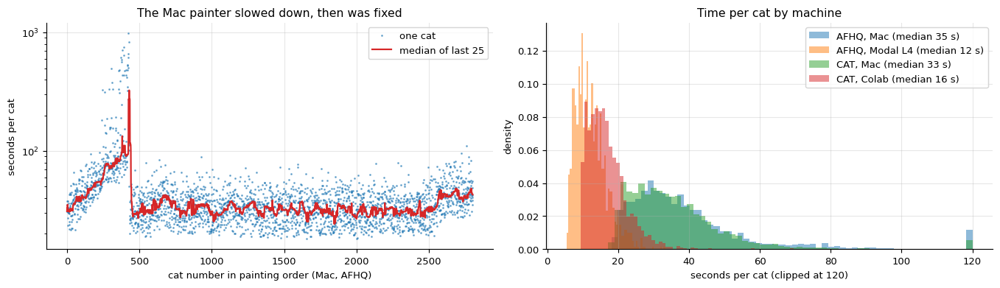

mean L1 to the photo by source: {'AFHQ Mac': 0.0341, 'AFHQ Modal': 0.033, 'CAT Mac': 0.027, 'CAT Colab': 0.0274}


In [13]:
A = jl(ML / "data/processed/afhq_brush_face/log.jsonl")                  # AFHQ on the Mac (MPS GPU)
M = jl(ML / "data/processed/afhq_brush_face/log_modal.jsonl")            # AFHQ on Modal L4 GPUs
C = [r for r in jl(ML / "data/processed/cat_brush_face/log.jsonl") if "seconds" in r]   # CAT dataset: Mac and Colab
C_mac = [r for r in C if r.get("painted_on") != "colab"]
C_colab = [r for r in C if r.get("painted_on") == "colab"]
groups = {"AFHQ, Mac": [r["seconds"] for r in A], "AFHQ, Modal L4": [r["seconds"] for r in M],
          "CAT, Mac": [r["seconds"] for r in C_mac], "CAT, Colab": [r["seconds"] for r in C_colab]}

summary = pd.DataFrame({k: {"cats": len(v), "median s": round(float(np.median(v)), 1), "mean s": round(float(np.mean(v)), 1),
                            "first 40 median s": round(float(np.median(v[:40])), 1)} for k, v in groups.items()}).T
display(summary)
print("Colab GPUs in the log:", dict(Counter(r.get("gpu") for r in C_colab)))
for k, v in groups.items():
    ver(f"seconds per cat, {k}: median / mean", (round(float(np.median(v)), 1), round(float(np.mean(v)), 1)),
        {"AFHQ, Mac": "afhq_brush_face/log.jsonl", "AFHQ, Modal L4": "afhq_brush_face/log_modal.jsonl"}.get(k, "cat_brush_face/log.jsonl"),
        "computed here")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
s = np.array(groups["AFHQ, Mac"])
ax[0].plot(s, ".", ms=2, alpha=0.5, label="one cat")
roll = [np.median(s[max(0, i - 24):i + 1]) for i in range(len(s))]
ax[0].plot(roll, color="tab:red", label="median of last 25")
ax[0].set(yscale="log", xlabel="cat number in painting order (Mac, AFHQ)", ylabel="seconds per cat", title="The Mac painter slowed down, then was fixed")
ax[0].legend()
for k, v in groups.items():
    ax[1].hist(np.clip(v, 0, 120), bins=60, alpha=0.5, label=f"{k} (median {np.median(v):.0f} s)", density=True)
ax[1].set(xlabel="seconds per cat (clipped at 120)", ylabel="density", title="Time per cat by machine")
ax[1].legend()
plt.tight_layout()
plt.show()
l1 = {k: np.mean([r["l1"] for r in v]) for k, v in (("AFHQ Mac", A), ("AFHQ Modal", M), ("CAT Mac", C_mac), ("CAT Colab", C_colab))}
print("mean L1 to the photo by source:", {k: round(float(v), 4) for k, v in l1.items()})

On the Mac a cat takes about 33 to 35 seconds (median 35 s for AFHQ, 33 s for the CAT dataset; the first 40 AFHQ cats took 31 s); on a Modal L4 GPU
about 12 s and on a Colab T4 about 16 s. The left panel is a real incident worth keeping in the record: the AFHQ painting job
slowed from about 32 s a cat to about 300 s (worst 992 s) over 11.7 hours as the Mac GPU's memory piled up (devlog 2026-10-10
§10.7). The fix was to drop each cat's tensors, run the garbage collector and empty the MPS cache after every cat, plus a
**watchdog** that stops any GPU loop whose recent median exceeds 2.5 times its first timings. The painter and the trainer
both carry it now. A smaller rise at the end of the left panel (about 45 s a cat after cat 2,500) is not explained in the record. All machines run the same painter code,
and within one dataset the logged L1 agrees across machines (AFHQ: Mac 0.0341, Modal 0.0330; CAT: Mac 0.0269, Colab 0.0271), so mixing Mac, Modal and
Colab cats in one training set does not mix different painters. The two datasets differ from each other (CAT 0.027 against AFHQ 0.033 to 0.034): their faces are
cut from photos of different sizes and framing, so the L1 is not comparable across datasets.

## 4. The bug: 0 of 256 sampled paintings could be turned back into a picture

This section reports what the record supports and says where it does not.

### 4.1 What happened

The first end-to-end trial (Kaggle, 2 × T4, d512 × 7 layers, 8 heads, **27,885,568 parameters**, 400 and 809 training cats,
devlog 2026-10-11 §2) showed this:

| | 400 cats | 809 cats |
|---|---|---|
| best validation loss | 4.469 | 4.296 |
| decodable samples of 256 (T = 1.0) | **0** | **0** |
| tokens in the right field | 85.1% | 84.5% |
| FID, validation vs training renders | 78.8 | 77.3 |

The model trained normally (validation loss fell, more data helped), yet **none of 256 sampled token sequences could be
turned back into a painting**; nothing could be drawn. "Decodable" is defined in `brushgpt.evaluate` as: every one of the
3,046 tokens lies inside the range its position allows (position 7 must be an *x* token, position 8 a *y* token, …). About
15% of sampled tokens landed in the wrong field. Looking at 8 samples on the CPU, the first wrong token appeared at positions
16 to 792, for example a size token where a colour belongs.

In [14]:
lo, hi, slot = G.LO, G.HI, G.SLOT
span = hi - lo + 1
tab = pd.DataFrame({"slot": [G.SLOTS[s] for s in slot], "allowed tokens": span}).groupby("slot").agg(positions=("slot", "size"), allowed=("allowed tokens", "first"))
tab["share of the 7,499-token vocabulary"] = (tab["allowed"] / T.VOCAB).map("{:.1%}".format)
display(tab.loc[["marker", "x", "y", "angle", "size", "paint"]])

# a constructed demonstration (NOT the trial's output, which was not saved): break one token of a real painting
row = z["tokens"][demo].copy()
pos = 2 + 5 * 10                                   # the x slot of stroke 11 of stage 1
wrong_field = row.copy()
wrong_field[pos] = T.OFFSET["paint"] + 123          # a colour token where an x token belongs
shifted = row.copy()
shifted[pos] = T.STAGE0 + 1                         # a stage marker in the middle of a stage
for name, r in (("original", row), ("one x token replaced by a colour token", wrong_field), ("one x token replaced by a stage marker", shifted)):
    ok = G.valid(r[None])[0]
    try:
        img = G.render(r)
        d = float(np.abs(img - G.render(row)).mean())
        out = f"renders, mean pixel change vs original {d:.4f}"
    except Exception as e:
        out = f"cannot be rendered: {type(e).__name__}"
    print(f"{name:45s} tokens out of range: {int((~ok).sum())}   {out}")

n = G.SEQ
for p in (0.15, 0.01, 0.001):
    print(f"if each of {n} tokens is wrong with probability {p}: P(a whole sample is valid) = {(1 - p) ** n:.3g}")
ver("trial: decodable samples of 256, tokens in right field (809 cats)", (0, 0.845), "docs/devlog/2026-10-11.md §2", "quoted")

,positions,allowed,"share of the 7,499-token vocabulary"
slot,,,
marker,6,1,0.0%
x,608,256,3.4%
y,608,256,3.4%
angle,608,32,0.4%
size,608,36,0.5%
paint,608,6912,92.2%


original                                      tokens out of range: 0   renders, mean pixel change vs original 0.0000


one x token replaced by a colour token        tokens out of range: 1   renders, mean pixel change vs original 0.0162


one x token replaced by a stage marker        tokens out of range: 1   renders, mean pixel change vs original 0.0655
if each of 3046 tokens is wrong with probability 0.15: P(a whole sample is valid) = 1.02e-215
if each of 3046 tokens is wrong with probability 0.01: P(a whole sample is valid) = 5.07e-14
if each of 3046 tokens is wrong with probability 0.001: P(a whole sample is valid) = 0.0475


(0, 0.845)

The first output shows the structure the bug lives in. Only 256 of the 7,499 tokens may appear at an *x* position (3.4%);
a size position allows 36 (0.5%). A model that spreads even a tiny probability over the thousands of wrong tokens, and
is *sampled at temperature 1*, will sometimes pick one. The second block is a **constructed** demonstration (the trial's
own samples were not saved): one wrong token in one painting either shifts all following strokes (the stage marker, whose
5-token grouping is then off by one) or paints a stroke with a nonsense value. The arithmetic shows why 0 of 256 is
not surprising: if only 1 token in 100 is in the wrong field, the probability that all 3,046 are right is below
10⁻¹³; at 15% it is zero for any practical purpose. The *decoder and encoder were never the problem*: section 3.3's
round-trip check passes on every real painting.

### 4.2 The fix, and how sure we can be about it

The fix is in `brushgpt.py` (the `heads` option): **one output layer per field**. Because every painting has the same
layout, every position is a known field, and in training and in sampling the token at that position is chosen only among
that field's tokens. It is implemented by using, at each position, only that field's rows of the shared (tied) output
table: the same as five output layers, one per field, that share weights with the input embedding. The model still
decides every value; what is fixed is the data's own layout. The code's docstring records that this was decided by the
project owner on 2026-10-11, after the question "architecture or patch?" was put to the owner in the devlog.

What the record supports, and what it does not:

* **Supported.** From run C onward the sampled paintings are all decodable: 256 of 256 (run C: devlog 2026-10-11 §7; runs
  D to I: `eval.json`, `decoded_rate 1.0`, `token_valid_rate 1.0`).
* **Not isolated.** Run C changed three things at once relative to the trial: the output layers, the stroke order
  (overlap, section 3.3) and the amount of data (1,639 training cats instead of 809). The Modal script defines
  ablations that would separate them (`A_list`, `B_overlap`, `C_overlap_heads`), but only the results of C were kept: **the
  effect of the per-field layers alone is not measured**.
* **By construction.** With the restriction on, an invalid token has probability zero, so 256 of 256 decodable is
  guaranteed and says nothing about how well the model learned. The honest quality numbers are the losses, FID and eye
  judge in section 5.
* **Where the standard stands.** The project's ground rules allow changes to "the model and how it is trained". The restriction is
  applied in training as well as in sampling, so the model learns under it; but it is a fixed property of the data's
  layout that the model is told rather than a thing it learns. It is not on the project's list of parts that predate the
  rule and do not meet it. We report it as an owner-approved design decision and name it here so a reader can judge.
* **A related slip.** Run C's evaluation then crashed in the FID step (`scipy.linalg.sqrtm` no longer takes the `disp`
  argument pytorch-fid passes), so C has no FID. The function is now computed in the repository's own code.

### 4.3 What we could not find

* The Kaggle trial's own logs and samples were not kept in the repository (`ml/runs/brushgpt/` starts at run C), so the
  numbers above are the ones the devlog recorded, and the "first wrong token at positions 16 to 792" comes from there.
* There is no git history for any of this code: the brush-painting files are still untracked (commits wait for the
  owner's review), so `git log` cannot show when or in which commit the fix was made. The docstring and devlog are the evidence.
* *Why* the model leaks probability into other fields at all (a shared output layer over 7,499 tokens, position
  embeddings that must learn the layout from only 809 cats) is our reading; no experiment in the repository isolates
  it, for the reason above.

## 5. Results: runs C to I

All runs: the same Brush GPT (d512, 7 layers, 8 heads, 27.9 M parameters; 27,894,784 with the 18 face-point tokens), batch 8
× accumulation 2, lr 3e-4 with 100 warm-up steps, mirror images added to the training set, early stop on validation loss,
one Modal A100-40GB per run (about $1 a run; 8 to 16 minutes of training until the early stop). Each run is tied to the frozen token file it used
(`docs/model-versions.md`), so it can be reproduced even though the data is still growing.

| run | what changed | why we tried it |
|---|---|---|
| **C** | trial data (1,639 train cats), overlap stroke order, per-field output layers | fix the undecodable samples (section 4) and the unpredictable x |
| **D** | all 4,085 cats (3,413 train) | more data should keep helping |
| **E** | + the nine face points written first (18 x/y tokens after BOS) | the shape GPT, whose cats always had eyes, did this: the model decides where the eyes are *before* painting small strokes |
| **F** | the loss of strokes within 0.35 eye distances of an eye counts 3× | spend more of the training signal on the eyes |
| **G** | E + F | |
| **H** | D, but every painting moved, turned and scaled so the eyes are level at fixed pixels (no repainting) | the shape GPT used aligned faces; alignment removes the position variation the model otherwise has to learn |
| **I** | H + E + F: aligned, face points first, eye weight 3 | combine |

Two further ideas from the shape GPT were considered and **not** done: making each eye its own step in the sequence
(it cannot be had by re-ordering, because overlapping strokes must keep their order; grouping the eye strokes as far as that
allows only takes the last stage from 21.6 to 17.8 separate runs, and would need the painter to paint the eyes in a pass of its
own, i.e. painting every cat again), and clustering eye colours separately (not needed: the training paintings already show clear eyes). Both from devlog 2026-10-12 §1.

In [15]:
info, mets, evals = {}, {}, {}
for n in NAMES:
    info[n] = json.loads(need(RUNS / n / "config.json").read_text())
    mets[n] = [r for r in jl(RUNS / n / "metrics.jsonl") if "val_loss" in r]
    if (RUNS / n / "eval.json").exists():
        evals[n] = json.loads(need(RUNS / n / "eval.json").read_text())

# eye judge, generated / real (quoted: raw judge outputs were not saved; see section 6 for what we re-measured)
EYE = {"D_all_cats": (0.501, 0.420, 0.007), "E_points": (0.501, 0.438, 0.007), "F_eye_weight": (0.501, 0.434, 0.006),
       "G_points_eyes": (0.501, 0.451, 0.006), "H_aligned": (0.537, 0.479, 0.006), "I_aligned_points_eyes": (0.537, 0.488, 0.006)}
EYE_LOSS_QUOTED = {"D_all_cats": 4.036}          # docs/model-versions.md: D's metrics.jsonl has no eye slot
ver("run D: eye-stroke loss", 4.036, "docs/model-versions.md (Brush GPT table)", "quoted")
rows = []
for n in NAMES:
    best = min(mets[n], key=lambda r: r["val_loss"])
    c = info[n]["config"]
    flags = [f for f, on in (("overlap", c["order"] == "overlap"), ("heads", c["heads"]), ("points", c.get("points")),
                             (f"eye x{c.get('eye_weight', 1):g}", c.get("eye_weight", 1) != 1)) if on]
    e = evals.get(n, {})
    ey = EYE.get(n)
    eye_loss = best["val_slots"].get("eye", EYE_LOSS_QUOTED.get(n))      # D's metrics predate the eye slot
    rows.append({"run": SHORT[n], "data": "trial" if n.startswith("C") else ("aligned" if n[0] in "HI" else "DEFG"),
                 "flags": " ".join(flags), "train cats": info[n]["train_cats"], "params (M)": round(info[n]["parameters"] / 1e6, 2),
                 "best step": best["step"], "epochs": best["epoch"], "min": best["minutes"],
                 "best val": best["val_loss"], "eye-stroke loss": eye_loss, "train loss": best["train_loss"],
                 "FID": round(e["fid_gen_vs_train"], 1) if e.get("fid_gen_vs_train") else None,
                 "decoded /256": e.get("decoded", "256 (devlog)" if n.startswith("C") else None),
                 "eye judge gen / real": f"{ey[1]:.3f} / {ey[0]:.3f} = {ey[1] / ey[0]:.2f}" if ey else None})
tab = pd.DataFrame(rows).set_index("run")
display(tab)
for n in NAMES:
    best = min(mets[n], key=lambda r: r["val_loss"])
    ver(f"run {SHORT[n]}: best validation loss (step)", (best["val_loss"], best["step"]), f"runs/brushgpt/{n}/metrics.jsonl", "computed here")
    if n in evals:
        ver(f"run {SHORT[n]}: FID of 256 samples vs training renders", round(evals[n]["fid_gen_vs_train"], 1), f"runs/brushgpt/{n}/eval.json", "computed here")
    if n in EYE:
        ver(f"run {SHORT[n]}: eye judge real / generated (SE)", EYE[n], "docs/devlog/2026-10-12.md §1, §5 and docs/model-versions.md", "quoted")
ver("run C FID", "not measured (the evaluation crashed in the FID step)", "runs/brushgpt/C_overlap_heads/eval.log", "not measured")

,data,flags,train cats,params (M),best step,epochs,min,best val,eye-stroke loss,train loss,FID,decoded /256,eye judge gen / real
run,,,,,,,,,,,,,
C,trial,overlap heads,1639,27.89,1600,7.81,5.8,4.0417,NaN,3.9272,NaN,256 (devlog),None
D,DEFG,overlap heads,3413,27.89,2900,6.80,11.0,3.9331,4.0360,3.8820,209.4,256,0.420 / 0.501 = 0.84
E,DEFG,overlap heads points,3413,27.89,2900,6.80,11.0,3.9166,3.9792,3.8667,208.6,256,0.438 / 0.501 = 0.87
F,DEFG,overlap heads eye x3,3413,27.89,2900,6.80,10.9,3.9609,3.9896,3.8888,232.5,256,0.434 / 0.501 = 0.87
G,DEFG,overlap heads points eye x3,3413,27.89,3400,7.97,12.8,3.9471,3.9315,3.8244,228.5,256,0.451 / 0.501 = 0.90
H,aligned,overlap heads,3413,27.89,2900,6.80,11.0,3.8860,3.9365,3.8176,193.6,256,0.479 / 0.537 = 0.89
I,aligned,overlap heads points eye x3,3413,27.89,2500,5.86,9.4,3.9152,3.8688,3.8297,182.5,256,0.488 / 0.537 = 0.91


'not measured (the evaluation crashed in the FID step)'

The table is the whole story in one place; the figures below pull it apart. Two cautions before reading it:

* **Validation loss is comparable only inside a group.** C used the trial's smaller validation set (153 cats); D to G share
  the same 292 validation cats; H and I use the *aligned* version of them, which is not quite the same task (the eyes are
  always in the same place, so the positions are easier to predict). So H's 3.886 and I's 3.915 are not "better than" D's 3.933;
  within D to G the differences are tiny (3.917 to 3.961) and every run is a single training with seed 0 (**run-to-run
  variance is not measured**).
* **The eye judge is the number that tracks the goal**, and it is reported as generated ÷ real because aligned real paintings
  already score higher (0.537) than unaligned ones (0.501). Its standard errors are about 0.006 to 0.007 on 128 samples (section 6).

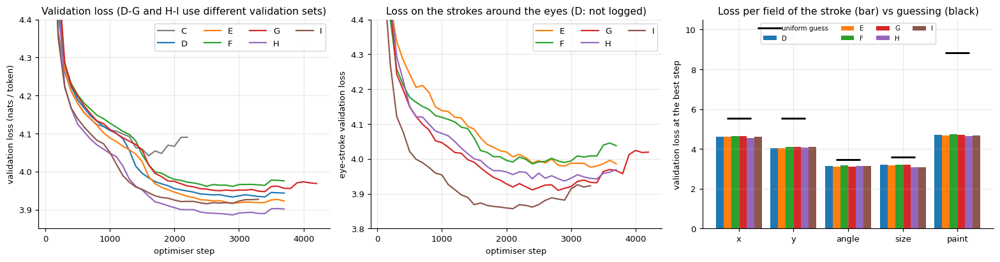

   marker      x      y  angle   size  paint  point    eye
D     0.0  4.607  4.040  3.156  3.196  4.698    NaN    NaN
E     0.0  4.598  4.052  3.118  3.184  4.663  3.171  3.979
F     0.0  4.634  4.091  3.166  3.208  4.738    NaN  3.990
G     0.0  4.641  4.090  3.125  3.202  4.709  3.180  3.932
H     0.0  4.556  4.060  3.133  3.065  4.648    NaN  3.936
I     0.0  4.600  4.116  3.130  3.078  4.684  2.562  3.869
uniform guess per field: {'x': np.float64(5.545), 'y': np.float64(5.545), 'angle': np.float64(3.466), 'size': np.float64(3.584), 'paint': np.float64(8.841)}


[4.607, 4.04, 3.156, 3.196, 4.698]

In [16]:
cols = dict(zip(NAMES, ["tab:gray", "tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for n in NAMES:
    m = mets[n]
    ax[0].plot([r["step"] for r in m], [r["val_loss"] for r in m], color=cols[n], label=SHORT[n])
    if "eye" in m[0]["val_slots"]:
        ax[1].plot([r["step"] for r in m], [r["val_slots"]["eye"] for r in m], color=cols[n], label=SHORT[n])
ax[0].set(ylim=(3.85, 4.4), xlabel="optimiser step", ylabel="validation loss (nats / token)", title="Validation loss (D-G and H-I use different validation sets)")
ax[1].set(ylim=(3.8, 4.4), xlabel="optimiser step", ylabel="eye-stroke validation loss", title="Loss on the strokes around the eyes (D: not logged)")
ax[0].legend(ncol=4)
ax[1].legend(ncol=3)
fields = ["x", "y", "angle", "size", "paint"]
xb = np.arange(len(fields))
for i, n in enumerate(NAMES[1:]):
    best = min(mets[n], key=lambda r: r["val_loss"])
    ax[2].bar(xb + (i - 2.5) * 0.14, [best["val_slots"][f] for f in fields], 0.14, color=cols[n], label=SHORT[n])
uniform = [np.log(256), np.log(256), np.log(32), np.log(36), np.log(6912)]
ax[2].plot(xb, uniform, "k_", ms=26, mew=2, label="uniform guess")
ax[2].set_xticks(xb)
ax[2].set_xticklabels(fields)
ax[2].set(ylabel="validation loss at the best step", title="Loss per field of the stroke (bar) vs guessing (black)")
ax[2].set_ylim(0, 10.5)
ax[2].legend(ncol=4, fontsize=7, loc="upper center")
plt.tight_layout()
plt.show()
best_slots = {SHORT[n]: min(mets[n], key=lambda r: r["val_loss"])["val_slots"] for n in NAMES[1:]}
print(pd.DataFrame(best_slots).T.round(3).to_string())
print("uniform guess per field:", dict(zip(fields, np.round(uniform, 3))))
ver("run D per-field validation loss x / y / angle / size / paint", [round(best_slots["D"][f], 3) for f in fields],
    "runs/brushgpt/D_all_cats/metrics.jsonl", "computed here")

**What the curves say.** (1) All runs fall quickly and flatten. The best validation loss comes at 5.9 to 8.0 epochs (steps 2,500 to 3,400; C at 7.8 epochs), the early stop fires 800 steps later
(steps 2,200 to 4,200, 8 to 16 minutes), and by then validation loss is 0.12 to 0.24 above training loss (run C, with half the cats, 0.32): the model starts to overfit its cats long
before it runs out of steps, so *more different cats, not more training*, is what can move it (this is what the CAT dataset is
for, section 7). (2) The per-field panel shows what is and is not learned. Compared with guessing (black ticks) the model is
**best at angle and size** (angle 3.15 against 3.47, size 3.2 against 3.58 for D), **mediocre at position** (x 4.61 against 5.55, y 4.04
against 5.55) and **worst, relative to its chance level, at colour** (4.7 against 8.84): colour is the field with 6,912 tokens.
Alignment (H, I) lowers the x and size losses slightly (x 4.56 and size 3.07 for H against D's 4.61 and 3.20; y does not move: 4.06 against 4.04), as expected when the
faces always sit in the same place. (3) Writing the face points first (E, G, I) costs the model about 2.5 to 3.2 nats per point
token (`point` slot), and after alignment the points are cheaper (I: 2.56 against G: 3.18), because eyes and mouth are now at nearly fixed
positions. (4) The eye-stroke loss is the one that moves in the direction we wanted: 4.036 (D), 3.979 (E), 3.990 (F), 3.932 (G), 3.937 (H),
3.869 (I).

,real,generated,+- SE,ratio,z vs D (raw generated),z vs previous row
run,,,,,,
D,0.501,0.420,0.007,0.838,NaN,None
E,0.501,0.438,0.007,0.874,1.8,None
F,0.501,0.434,0.006,0.866,1.5,None
G,0.501,0.451,0.006,0.900,3.4,1.4
H,0.537,0.479,0.006,0.892,6.4,None
I,0.537,0.488,0.006,0.909,7.4,1.1


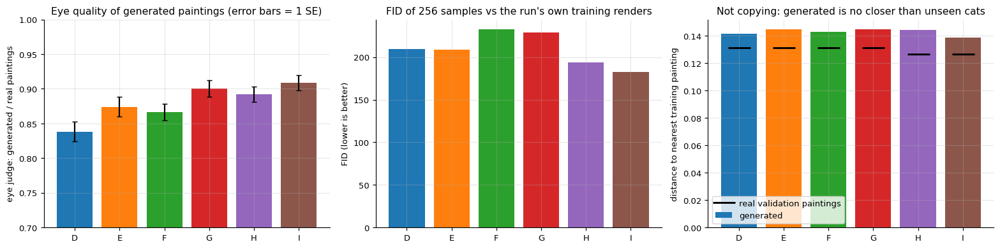

{'D': (0.1412, 0.131, 0), 'E': (0.1445, 0.131, 0), 'F': (0.1429, 0.131, 0), 'G': (0.1446, 0.131, 0), 'H': (0.1443, 0.1266, 0), 'I': (0.1386, 0.1266, 0)}
FID of the validation paintings themselves (D-G, H-I): 39.5 41.8


(39.5, 41.8)

In [17]:
# does each change beat D on the eye judge by more than noise?  z = difference of generated means / combined SE
d_gen, d_se = EYE["D_all_cats"][1], EYE["D_all_cats"][2]
rows = []
for n, (real, gen, se) in EYE.items():
    z_vs_d = (gen - d_gen) / np.hypot(se, d_se) if n != "D_all_cats" else float("nan")
    rows.append({"run": SHORT[n], "real": real, "generated": gen, "+- SE": se, "ratio": round(gen / real, 3),
                 "z vs D (raw generated)": round(z_vs_d, 1), "z vs previous row": None})
tab = pd.DataFrame(rows).set_index("run")
tab.loc["I", "z vs previous row"] = round((0.488 - 0.479) / np.hypot(0.006, 0.006), 1)        # I vs H, same real set
tab.loc["G", "z vs previous row"] = round((0.451 - 0.438) / np.hypot(0.006, 0.007), 1)        # G vs E
display(tab)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
names = [SHORT[n] for n in EYE]
ratio = [g / r for r, g, _ in EYE.values()]
err = [s / r for r, _, s in EYE.values()]
ax[0].bar(names, ratio, yerr=err, color=[cols[n] for n in EYE], capsize=3)
ax[0].set(ylim=(0.7, 1.0), ylabel="eye judge: generated / real paintings", title="Eye quality of generated paintings (error bars = 1 SE)")
fid = [evals[n]["fid_gen_vs_train"] for n in EYE]
ax[1].bar(names, fid, color=[cols[n] for n in EYE])
ax[1].set(ylabel="FID (lower is better)", title="FID of 256 samples vs the run's own training renders")
nn = [evals[n] for n in EYE]
ax[2].bar(names, [e["gen_nearest_train"]["median"] for e in nn], color=[cols[n] for n in EYE], label="generated")
ax[2].plot(names, [e["val_nearest_train"]["median"] for e in nn], "k_", ms=24, mew=2, label="real validation paintings")
ax[2].set(ylabel="distance to nearest training painting", title="Not copying: generated is no closer than unseen cats")
ax[2].legend()
plt.tight_layout()
plt.show()
print({SHORT[n]: (evals[n]["gen_nearest_train"]["median"], evals[n]["val_nearest_train"]["median"], evals[n]["gen_nearest_train"]["below_val_min"]) for n in EYE})
print("FID of the validation paintings themselves (D-G, H-I):", round(evals["D_all_cats"]["fid_val_vs_train"], 1), round(evals["H_aligned"]["fid_val_vs_train"], 1))
ver("FID of real validation paintings vs training renders (D-G / H-I)", (round(evals["D_all_cats"]["fid_val_vs_train"], 1), round(evals["H_aligned"]["fid_val_vs_train"], 1)),
    "runs/brushgpt/D_all_cats/eval.json, H_aligned/eval.json", "computed here")

### What each change did

**C → D: more cats (1,639 → 3,413 training cats).** Validation loss 4.042 → 3.933 and all 256 samples decode. The two
validation sets differ (D's contains the trial's validation cats plus new ones), so the loss comparison is soft; the clearer
signs are qualitative (below) and that FID against the training renders is 209 for generated paintings but 39 for real
validation paintings, so a long way remains. D copies nothing: generated paintings are no closer to a training painting (median
0.141) than unseen validation cats are (0.131), and none is closer than the closest validation cat (`below_val_min` is 0 for every run).

**D → E: face points first.** Validation loss 3.933 → 3.917, eye-stroke loss 4.036 → 3.979, eye ratio 0.84 → 0.87, FID unchanged (209).
Small, in the right direction, but the eye-score difference is 0.018 raw with a combined standard error of about 0.010: **not shown to be real**.

**D → F: eye weight 3.** Eye-stroke loss 4.036 → 3.990 and eye ratio 0.87, but validation loss is *worse* (3.961) and **FID is worse
(232 against 209)**: spending more of the signal on 14% of the tokens (`eye_token_share` 0.1417) took it from the rest. Alone, this did **not** help clearly.

**G = E + F.** Eye ratio 0.90, eye-stroke loss 3.932. This is the combination that beats D on the eye judge by more than three
standard errors (z in the table), though G's FID (229) is still worse than D's. The combination worked better than either part: the points
tell the model where the eyes are, and the weight makes it care.

**D → H: alignment.** Not comparable by validation loss (aligned task), but FID 209 → 194 and the real paintings' own FID changes from 39.5 to
41.8 (the reference changed, too). Eye ratio 0.89, eye-stroke loss 3.937. The model's samples show more face structure. Alignment needs no repainting
(`brushgpt.py align`: every stroke is moved, turned and scaled so the eyes are level; eye position spread on the canvas goes from about 11 px to 0).

**I = H + G.** The best on all four of our measures: eye ratio 0.91, eye-stroke loss 3.869, FID 182 (the lowest), median nearest-training distance 0.139.
The honest part: the gain of I over H on the eye judge (0.488 against 0.479) is about 1 standard error, so **I is not shown to be better than H on
eyes alone**; I's margin on FID (182 vs 194) and on eye-stroke loss (3.869 vs 3.937) is where it is ahead.

**Overall.** From D to I the eye score of generated paintings rises from 0.420 to 0.488 (the eye judge's own scale: real paintings 0.501 and 0.537), the FID from 209 to 182, and the
samples go from faces without eyes to faces whose eyes are usually visible, which the next figures show. It is still not solved: most
samples still do not show clear eyes in *every* painting, and the model has only ever seen 3,413 cats.

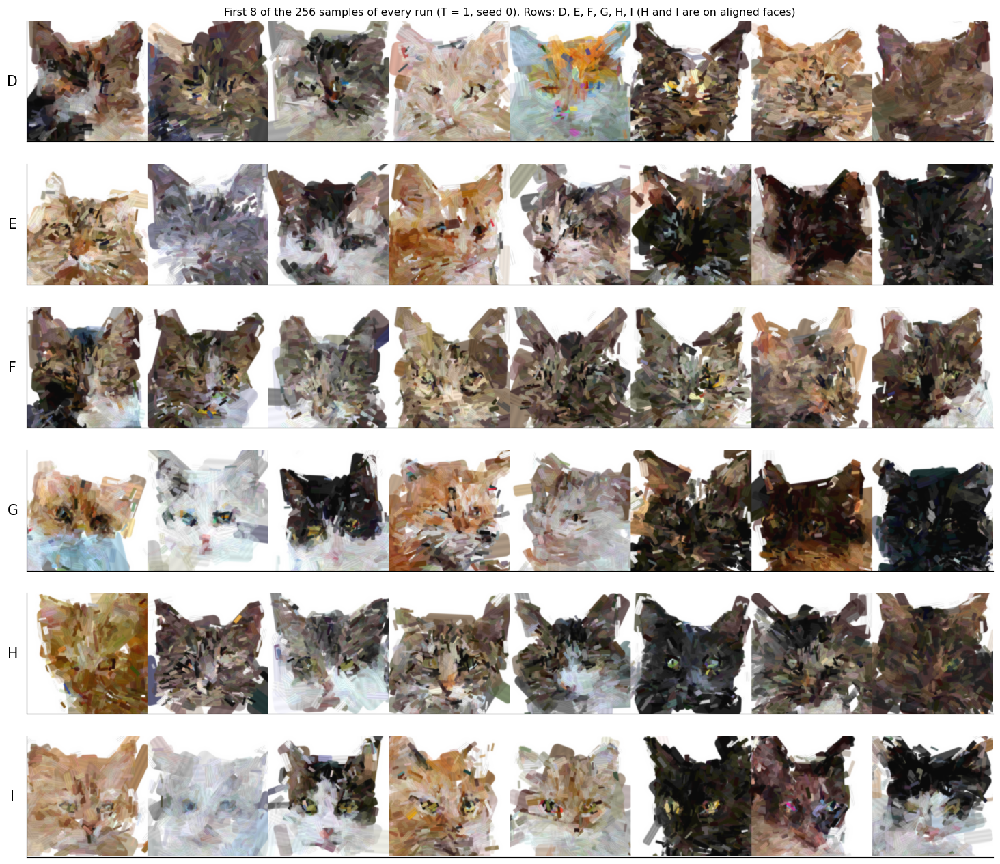

In [18]:
# same sampling seed in every run (brushgpt.sample, seed 0, temperature 1): the first row of each run's 32-sample sheet.
# Same seed means the same random stream, NOT the same cat: the models differ, so each row is a different set of cats.
order = [n for n in NAMES if n != "C_overlap_heads"]
sheets = [Image.open(need(RUNS / n / "samples.png")).convert("RGB").crop((0, 0, 2048, 256)) for n in order]
fig, ax = plt.subplots(len(order), 1, figsize=(14, 2.05 * len(order)))
for a, im, n in zip(ax, sheets, order):
    a.imshow(im)
    a.set_yticks([])
    a.set_xticks([])
    a.set_ylabel(SHORT[n], rotation=0, labelpad=14, fontsize=14, va="center")
    a.grid(False)
ax[0].set_title("First 8 of the 256 samples of every run (T = 1, seed 0). Rows: D, E, F, G, H, I (H and I are on aligned faces)")
plt.tight_layout()
plt.show()

Row D: coats and head shapes that look like cats (the colours are real cats' colours) but **no readable eyes**, mostly dark smudges. Rows E
and F are similar, and the changes are small, matching the table. Row G shows eyes in a few paintings. Rows H and I (aligned) show a clear step:
the face is centred, and in I **most paintings have two eyes in the right place**, often yellow-green with a dark pupil, and in several a
visible nose and mouth. Not all of them (the pale, low-contrast cats are still vague), and the strokes of the whole face are still
rougher than the training paintings. Nothing here was selected: they are the first eight samples of each run.

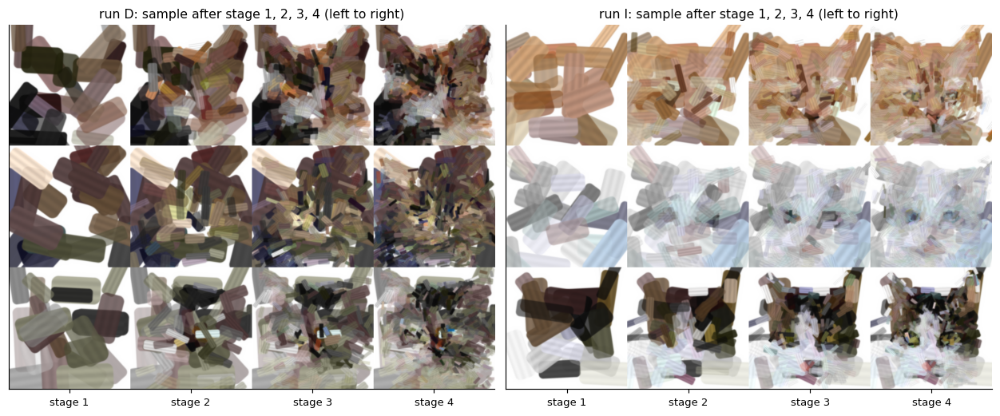

In [19]:
# the same four stages, for the first 3 samples of D and of I
def rows3(name):
    return Image.open(need(RUNS / name / "process.png")).convert("RGB").crop((0, 0, 1024, 768))


fig, ax = plt.subplots(1, 2, figsize=(12, 5.6))
for a, n in zip(ax, ("D_all_cats", "I_aligned_points_eyes")):
    a.imshow(rows3(n))
    a.set_title(f"run {SHORT[n]}: sample after stage 1, 2, 3, 4 (left to right)")
    a.set_xticks([128, 384, 640, 896])
    a.set_xticklabels(["stage 1", "stage 2", "stage 3", "stage 4"])
    a.set_yticks([])
    a.grid(False)
plt.tight_layout()
plt.show()

Generation really is a painting process: stage 1 is a few big blocks of colour that already fix the coat and a rough head; stage 2
refines the head and ears; in I the eyes usually first appear in stage 3, with the last 360 strokes sharpening them. The next section
measures exactly this.

## 6. How the eyes are learned, and how "eye quality" is measured

### 6.1 The judge

We needed a number for "does this painting show eyes" that does not depend on looking at pictures and that the generator
cannot game. `ml/tools/eye_judge.py` uses the landmark model of section 2.1 as an **independent judge**: it was trained on
photographs and never on paintings, and never on anything generated. A painting is given to it (shrunk into a padded frame as when
labelling AFHQ); it returns nine predicted points and a confidence for each (the peak of the heat map). The **eye score** is the mean
confidence of the two eye points, averaged over a set of paintings, with its **standard error** (the standard deviation over paintings divided by √n; this is the "±" used everywhere).
A painting with two clear eyes in the usual places gets a high score; a smudge gets a low one. Because aligned real paintings score higher than
unaligned ones, the fair comparison is **generated ÷ real** on the same kind of data.

The judge's confidence did not predict the *error* of its labels on photographs (AUROC 0.57, section 2.3), so what it measures is
"looks like an eye the model recognises", not "is in exactly the right spot". For comparing paintings that is what we need, but it is a proxy.

re-measured on 2026-10-14 14:59 on the cpu with the judge cat-face-landmarks runs/pose_mae
unaligned (runs D-G)   real validation paintings, 128: eye score 0.5006 +- 0.0070   (other 7 points 0.4355)
aligned (runs H, I)    real validation paintings, 128: eye score 0.5371 +- 0.0039   (other 7 points 0.4217)


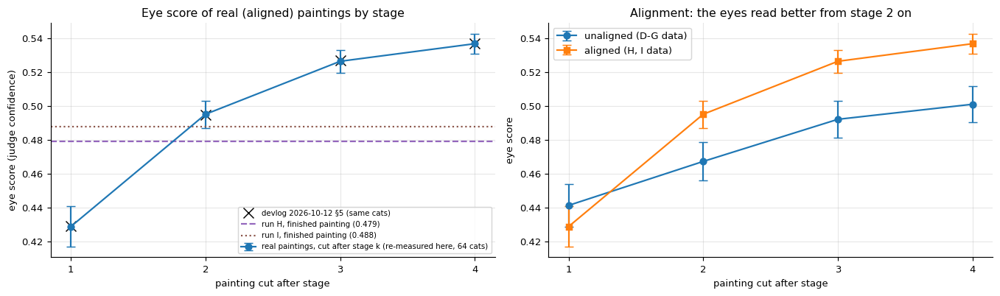

stage 1..1: aligned real 0.4288 +- 0.0119   unaligned real 0.4413 +- 0.0125
stage 1..2: aligned real 0.4952 +- 0.0081   unaligned real 0.4673 +- 0.0112
stage 1..3: aligned real 0.5265 +- 0.0068   unaligned real 0.4922 +- 0.0110
stage 1..4: aligned real 0.5369 +- 0.0060   unaligned real 0.5011 +- 0.0108


(0.479, 0.488)

In [20]:
er = json.loads(need(Path("_src/data_08/eye_real.json")).read_text())
print("re-measured on", er["measured"], "on the", er["device"], "with the judge", er["judge"])
for label in ("unaligned (runs D-G)", "aligned (runs H, I)"):
    f = er[label]["finished_128"]
    print(f"{label:22s} real validation paintings, 128: eye score {f['eye_conf_mean']:.4f} +- {f['eye_conf_se']:.4f}   (other 7 points {f['other_conf_mean']:.4f})")
ver("eye judge, real unaligned validation paintings (128): mean +- SE", (er["unaligned (runs D-G)"]["finished_128"]["eye_conf_mean"], er["unaligned (runs D-G)"]["finished_128"]["eye_conf_se"]),
    "_src/data_08/eye_real.json (make_08_assets.py); devlog says 0.501", "computed here")
ver("eye judge, real aligned validation paintings (128): mean +- SE", (er["aligned (runs H, I)"]["finished_128"]["eye_conf_mean"], er["aligned (runs H, I)"]["finished_128"]["eye_conf_se"]),
    "_src/data_08/eye_real.json; devlog says 0.537", "computed here")

# real paintings cut after stage k (64 aligned validation cats) vs the finished generated paintings
stage_real = er["aligned (runs H, I)"]["per_stage_64"]
devlog_stage = {"1": 0.429, "2": 0.495, "3": 0.527, "4": 0.537}
ks = ["1", "2", "3", "4"]
vals = [stage_real[k]["eye_conf_mean"] for k in ks]
ses = [stage_real[k]["eye_conf_se"] for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
ax[0].errorbar(range(1, 5), vals, yerr=ses, marker="o", capsize=4, label="real paintings, cut after stage k (re-measured here, 64 cats)")
ax[0].plot(range(1, 5), [devlog_stage[k] for k in ks], "x", color="k", ms=9, label="devlog 2026-10-12 §5 (same cats)")
ax[0].axhline(0.479, color="tab:purple", ls="--", label="run H, finished painting (0.479)")
ax[0].axhline(0.488, color="tab:brown", ls=":", label="run I, finished painting (0.488)")
ax[0].set(xticks=range(1, 5), xlabel="painting cut after stage", ylabel="eye score (judge confidence)", title="Eye score of real (aligned) paintings by stage")
ax[0].legend(fontsize=7, loc="lower right")
un = er["unaligned (runs D-G)"]["per_stage_64"]
ax[1].errorbar(range(1, 5), [un[k]["eye_conf_mean"] for k in ks], yerr=[un[k]["eye_conf_se"] for k in ks], marker="o", capsize=4, label="unaligned (D-G data)")
ax[1].errorbar(range(1, 5), vals, yerr=ses, marker="s", capsize=4, label="aligned (H, I data)")
ax[1].set(xticks=range(1, 5), xlabel="painting cut after stage", ylabel="eye score", title="Alignment: the eyes read better from stage 2 on")
ax[1].legend()
plt.tight_layout()
plt.show()
for k in ks:
    print(f"stage 1..{k}: aligned real {stage_real[k]['eye_conf_mean']:.4f} +- {stage_real[k]['eye_conf_se']:.4f}   unaligned real {un[k]['eye_conf_mean']:.4f} +- {un[k]['eye_conf_se']:.4f}")
ver("real aligned paintings, eye score after stage 1/2/3/4 (64 cats)", [round(v, 3) for v in vals], "_src/data_08/eye_real.json; devlog 0.429/0.495/0.527/0.537", "computed here")
ver("run H finished 0.479; run I finished 0.488 (generated, 128 samples)", (0.479, 0.488), "docs/devlog/2026-10-12.md §1, §5", "quoted")

### 6.2 Reading the stage-by-stage numbers

The **real** paintings' eye score rises with every stage: 0.429 after the big blocks only, 0.495 after stage 2, 0.527 after stage 3, 0.537
when finished (we re-measured these on the CPU from the saved token file and they reproduce the numbers in devlog 2026-10-12 §5 to within
0.001; the "±" at each stage is about 0.006 to 0.012). So the eyes in a *real* painting are readable by the judge already after the second stage, at
**0.495**.

Now compare with the model. A **finished** painting of run H scores **0.479**, *below* a real painting that stopped after stage 2; run I's finished
painting scores 0.488, still below it. So a whole generated painting shows its eyes less clearly than half a real one. This comparison alone cannot
say *which* stage the model gets wrong: a finished generated painting is the model's own stage 1, 2, 3 and 4 together, and its stage 4 is painted on top
of its own, possibly wrong, stage 3. Section 6.3 separates the stages by giving the model the real first stages and letting it paint only the rest.

### 6.3 Where the eyes are lost: let the model finish a real painting (paper idea P6)

**Where the method comes from.** Collaborative Neural Painting (Dall'Asen et al., arXiv 2312.01800, R1 in
`docs/paper-notes/brush-gpt-related-work.md`) paints in four coarse-to-fine levels, as we do, and evaluates its model on several
"interaction" tasks. One of them, *Granularity level* (their §5.1 and §6.2, Table 2), keeps the strokes of the first one to three levels of a
test painting and asks the model to paint the finer levels; the result is rendered and compared with the test painting (FID, a stroke L1 after
Hungarian matching, an image L2), pooled over the randomly chosen levels, on about 5,000 test sequences. Their model is a masked (non-autoregressive)
transformer trained with this masking; ours is autoregressive, so it can continue any real prefix without being trained for it.

**What we changed, and why.** We keep the real painting up to the end of stage *k* for every *k* separately (k = 0: only `BOS` and the nine face
points, so the model paints everything; k = 1, 2, 3), let run I sample the rest (temperature 1.0, the same seed for every k), and score the result with
the eye judge of section 6.1. Next to it we score the real first k stages alone, with nothing painted after them. Because the same 64 AFHQ
validation cats appear in every condition, each cat is compared with its own finished real painting (a *paired* difference, whose standard
error is smaller than that of two independent means). The difference "what the real later stages add" minus "what the model's later stages add"
then says how much of the gap to a real painting comes from the stages the model painted. We also report the teacher-forced cross-entropy of each
stage's stroke tokens, to see whether the loss points at the same stage. Tool: `ml/tools/stage_continuation.py` (CPU, 22 minutes).

run I, 64 AFHQ validation cats, temperature 1.0, seed 3; whole real painting: eye score 0.5369
 real stages given  real only   + model   gap to whole (paired)  real rest adds   model rest adds
                 0     0.1649    0.4889      -0.0480 +- 0.0107         +0.3721    +0.3240 +- 0.0083
                 1     0.4288    0.5135      -0.0234 +- 0.0079         +0.1082    +0.0848 +- 0.0139
                 2     0.4952    0.4998      -0.0371 +- 0.0101         +0.0417    +0.0046 +- 0.0112
                 3     0.5265    0.5178      -0.0192 +- 0.0071         +0.0105    -0.0087 +- 0.0069
model paints everything, face points too: 0.5117 +- 0.0075
teacher-forced loss per stage (stroke tokens): [4.1513, 4.166, 3.941, 3.8024]


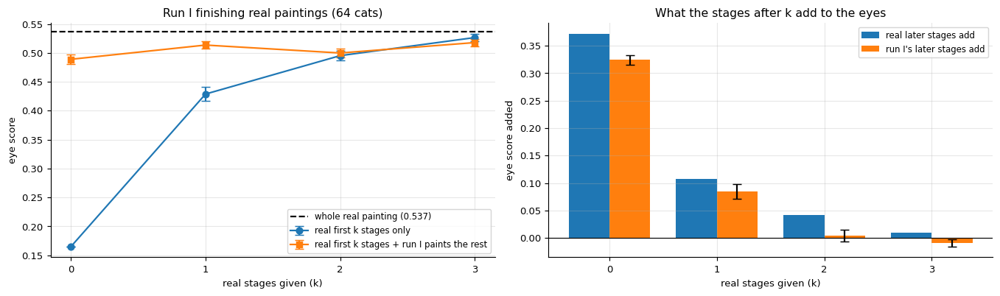

In [21]:
sc = json.loads(need(RUNS / "I_aligned_points_eyes/stage_continuation_afhq_t1.0.json").read_text())
z = np.load(need(RUNS / "I_aligned_points_eyes/stage_continuation_afhq_t1.0.npz"))
conf = {k[5:]: z[k] for k in z.files if k.startswith("conf_")}
def paired(a, b):
    d = conf[a] - conf[b]
    return float(d.mean()), float(d.std(ddof=1) / np.sqrt(len(d)))
whole = sc["whole_real"]["eye_conf_mean"]
print(f"run I, {sc['n']} AFHQ validation cats, temperature {sc['temperature']}, seed {sc['seed']}; whole real painting: eye score {whole:.4f}")
print(f"{'real stages given':>18s} {'real only':>10s} {'+ model':>9s} {'gap to whole (paired)':>23s} {'real rest adds':>15s} {'model rest adds':>17s}")
added = []
for k in range(4):
    nxt = "whole_real"
    ro, mo = sc["real_first"][str(k)], sc["model_after"][str(k)]
    real_add = paired(nxt, f"real_first_{k}")
    model_add = paired(f"model_after_{k}", f"real_first_{k}")
    added.append((real_add, model_add))
    print(f"{k:>18d} {ro['eye_conf_mean']:>10.4f} {mo['eye_conf_mean']:>9.4f} {mo['paired_diff']:>+12.4f} +- {mo['paired_diff_se']:.4f} "
          f"{real_add[0]:>+15.4f} {model_add[0]:>+10.4f} +- {model_add[1]:.4f}")
print(f"model paints everything, face points too: {sc['free']['eye_conf_mean']:.4f} +- {sc['free']['eye_conf_se']:.4f}")
print("teacher-forced loss per stage (stroke tokens):", sc["stage_loss"])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
ks = np.arange(4)
ax[0].errorbar(ks, [sc["real_first"][str(k)]["eye_conf_mean"] for k in ks], yerr=[sc["real_first"][str(k)]["eye_conf_se"] for k in ks],
               marker="o", capsize=4, label="real first k stages only")
ax[0].errorbar(ks, [sc["model_after"][str(k)]["eye_conf_mean"] for k in ks], yerr=[sc["model_after"][str(k)]["eye_conf_se"] for k in ks],
               marker="s", capsize=4, label="real first k stages + run I paints the rest")
ax[0].axhline(whole, color="k", ls="--", label=f"whole real painting ({whole:.3f})")
ax[0].set(xticks=ks, xlabel="real stages given (k)", ylabel="eye score", title="Run I finishing real paintings (64 cats)")
ax[0].legend(fontsize=8, loc="lower right")
w = 0.38
ax[1].bar(ks - w / 2, [a[0][0] for a in added], w, label="real later stages add")
ax[1].bar(ks + w / 2, [a[1][0] for a in added], w, yerr=[a[1][1] for a in added], capsize=4, label="run I's later stages add")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xticks=ks, xlabel="real stages given (k)", ylabel="eye score added", title="What the stages after k add to the eyes")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
ver("run I stage continuation: eye score with real first k = 0..3 stages + model (64 cats)",
    [sc["model_after"][str(k)]["eye_conf_mean"] for k in range(4)], "runs/brushgpt/I_aligned_points_eyes/stage_continuation_afhq_t1.0.json", "computed here")
ver("run I: what its stages 3-4 add (given real 1-2) vs what the real ones add", (round(added[2][1][0], 4), round(added[2][0][0], 4)),
    "runs/brushgpt/I_aligned_points_eyes/stage_continuation_afhq_t1.0.npz (paired)", "computed here")
ver("run I teacher-forced loss of stages 1..4", sc["stage_loss"], "runs/brushgpt/I_aligned_points_eyes/stage_continuation_afhq_t1.0.json", "computed here")
jf = RUNS / "J_cat_aligned_points_eyes/stage_continuation_afhq_t1.0.json"
if jf.exists():
    sj = json.loads(jf.read_text())
    print("run J, same cats:", [sj["model_after"][str(k)]["eye_conf_mean"] for k in range(4)])
    ver("run J stage continuation (same 64 cats)", [sj["model_after"][str(k)]["eye_conf_mean"] for k in range(4)], str(jf.relative_to(ML)), "computed here")
else:
    ver("run J stage continuation", "not measured", "J is still training; tools/run_stage_continuation_J.sh runs it when J finishes", "not measured")

**What it shows (64 cats, one seed, one judge).**

1. **The two finest stages are where run I loses the eyes.** Given the real stages 1–2, the real stages 3–4 add 0.042 to the eye score; run I's own
   stages 3–4 add 0.005 ± 0.011, indistinguishable from nothing. Given the real stages 1–3, run I's stage 4 (360 strokes) leaves the eyes slightly
   *less* readable than not painting it at all (−0.009 ± 0.007, 1.3 standard errors: not yet certain), where the real stage 4 adds 0.011.
2. **Stage 1 also costs something.** Giving the model the real stage 1 (24 strokes) shrinks the gap to the whole real painting from 0.048 to 0.023
   (a difference of 0.025 ± 0.011, 2.3 standard errors).
3. The gaps after k = 1 and k = 2 (0.023 and 0.037) differ by less than their noise; they do not show that more real stages make things worse.
4. **The per-token loss points the other way.** Stages 1 and 2 have the highest loss (4.15, 4.17) and stage 4 the lowest (3.80), yet stage 4 is where
   the eyes are lost. A low loss per token in the fine stages is expected (many small strokes, each predictable from its neighbours) and says nothing
   about whether the few strokes that make an eye are right; where the visible errors arise has to be measured on the pictures.
5. Letting the model also write the face points (0.512) scored 0.023 ± 0.012 *higher* than giving it the real face points (0.489); 1.8 standard errors,
   so only a hint, perhaps that the model's own face points are more typical and easier to paint.

**How this differs from R1.** R1 reports one pooled number per task and no breakdown by level, and does not compare against its own loss. Splitting
by stage and pairing each cat with its own painting is what lets the gap be attributed to a stage. This replaces the earlier reading of section 6.2,
which, from finished paintings alone, had attributed the errors to the coarse and middle stages; with the stages separated, the evidence points to
the finest stages (and, less strongly, the first). What would fix the fine stages is open: the colour vocabulary (P2), letting the model see its
canvas (P8), or the stroke order within a stage (P7). Run J is measured on the same 64 cats when it finishes.

## 7. Where we are: the CAT dataset paintings

The runs above all use AFHQ's 3,413 training cats, and the data is the limit: the model overfits after about 6 to 8 epochs. The remedy the
literature supports is more data from the same distribution (the project's idea **P3**, `docs/paper-ideas.md`): paint the CAT dataset's cats the same way.
Their faces are smaller and looser than AFHQ's, so their paintings carry less detail, but they have the nine hand-placed points (no landmark model's
guess is needed) and there are thousands of them. `ml/tools/paint_cat_dataset.py` does it:

* the same painter, four stages, snapped to the token grid; the same face square (points' box + 20%);
* a cat whose subject mask misses an eye is **skipped** before painting (it would be painted white);
* every painted cat logs four **eye measures** (`eye_l1`: error against the photo inside the eye discs; `eye_conf`: the eye judge's score on the painting;
  `eye_conf_photo`: on the photo it copies; `eye_err`: how far the judge finds the painting's eyes from the hand-labelled ones). The project decided to
  *drop badly painted cats* but to set the threshold later, from the distribution of these numbers. The threshold was set on 2026-10-16
  (section 7.1).
* two machines paint disjoint parts of the list (`tools/run_mac_paint.sh`: the Mac paints the first 4,065 cats of the training list; `tools/prepare_colab_paint.py`: a free Colab GPU paints
  the last 2,973), and `tools/merge_colab_paint.py` merges Colab's cats in and computes their eye measures on the CPU. When Colab stopped
  (2026-10-16), the Mac painted what Colab had not reached; nothing was painted twice.

checked 2026-10-16 20:25.  .npz paintings in cat_brush_face: 6983
CAT training list: 7065 cats.  Mac share = first 4,065: painted 4010, skipped (eye outside mask) 32
rest of the list (3000): painted 2973;  Colab job list: 2973 cats
painted by machine (from the log): Mac 4793, Colab 2191;  cats skipped for a masked-out eye: 49


cats of the list with no subject mask (never painted): 33;  painted + skipped + no mask = 7065 of 7065


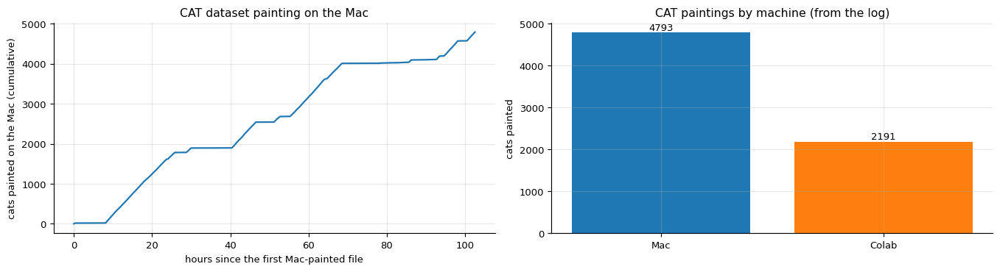

In [22]:
cat_dir = ML / "data/processed/cat_brush_face"
files = sorted(cat_dir.glob("*.npz"))
now = time.strftime("%Y-%m-%d %H:%M")
listing = [str(i) for i in np.load(need(ML / "data/processed/catface/train.npz"))["ids"]]
job = json.loads(need(REPO / "data/colab_paint/pkg/job.json").read_text())
skipped = [r for r in jl(cat_dir / "log.jsonl") if "skipped" in r]


def stem_of(full_id):
    zstem, member = full_id.split("/", 1)
    return Path(f"{zstem}__{member.replace('/', '__')}").stem


painted = {f.stem for f in files}
first, rest = listing[:4065], listing[4065:]
print(f"checked {now}.  .npz paintings in cat_brush_face: {len(files)}")
print(f"CAT training list: {len(listing)} cats.  Mac share = first 4,065: painted {sum(stem_of(i) in painted for i in first)}, skipped (eye outside mask) "
      f"{sum(1 for r in skipped if r['id'] in set(first))}")
print(f"rest of the list ({len(rest)}): painted {sum(stem_of(i) in painted for i in rest)};  Colab job list: {len(job)} cats")
print(f"painted by machine (from the log): Mac {len(C_mac)}, Colab {len(C_colab)};  cats skipped for a masked-out eye: {len(skipped)}")
no_mask = [i for i in listing if not (ML / "data/raw/cat_dataset/masks" / f"{stem_of(i)}_mask1.png").exists()]
print(f"cats of the list with no subject mask (never painted): {len(no_mask)};  painted + skipped + no mask = "
      f"{len(painted & {stem_of(i) for i in listing}) + len(skipped) + len(no_mask)} of {len(listing)}")
ver("CAT cats with no subject mask", len(no_mask), "ml/data/raw/cat_dataset/masks", "computed here")
ver("CAT paintings (.npz) at execution time", (len(files), now), "ml/data/processed/cat_brush_face/*.npz", "computed here")
ver("CAT training list size / Mac share / Colab job", (len(listing), 4065, len(job)), "catface/train.npz; run_mac_paint.sh; colab_paint/pkg/job.json", "computed here")
ver("CAT cats skipped (eyes outside the subject mask)", len(skipped), "cat_brush_face/log.jsonl", "computed here")

# painting over time on the Mac (file modification time; Colab files carry the time they were merged, so they are left out)
colab_stems = {Path(r["id"].split("/", 1)[0] + "__" + r["id"].split("/", 1)[1].replace("/", "__")).stem for r in C_colab}
t = np.array(sorted(f.stat().st_mtime for f in files if f.stem not in colab_stems))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot((t - t[0]) / 3600, np.arange(1, len(t) + 1))
ax[0].set(xlabel="hours since the first Mac-painted file", ylabel="cats painted on the Mac (cumulative)", title="CAT dataset painting on the Mac")
cum = {"Mac": len(C_mac), "Colab": len(C_colab)}
ax[1].bar(list(cum), list(cum.values()), color=["tab:blue", "tab:orange"])
ax[1].set(ylabel="cats painted", title="CAT paintings by machine (from the log)")
for i, v in enumerate(cum.values()):
    ax[1].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

6965 painted CAT cats with eye measures
   eye_conf (painting)        5/25/50/75/95th percentile: [0.3686, 0.4389, 0.4927, 0.5474, 0.6282]
   eye_conf_photo (photo)     5/25/50/75/95th percentile: [0.3716, 0.4417, 0.4957, 0.5512, 0.63]
   eye_err (eye distances)    5/25/50/75/95th percentile: [0.0151, 0.0264, 0.0378, 0.0541, 0.1045]
   eye_l1 (in the eye discs)  5/25/50/75/95th percentile: [0.0215, 0.0304, 0.0391, 0.0512, 0.0743]
median of eye_conf / eye_conf_photo per cat: 0.995
left out: painting eye score below 0.85 of the photo's 73, eyes more than 0.2 eye distances off 73, both 11; in all 135 of 6965 (1.9%)
tokens_J.npz (the data of run J): 10933 paintings; {'train': {'AFHQ': 3413, 'CAT': 6327}, 'val': {'AFHQ': 292, 'CAT': 521}, 'test': {'AFHQ': 380, 'CAT': 0}}


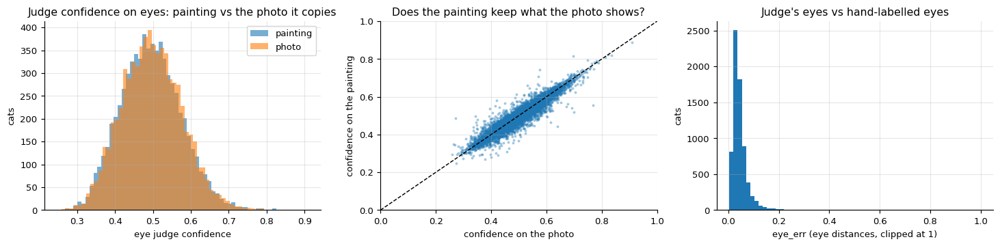

In [23]:
ok = [r for r in C if "eye_conf" in r]
conf, phot, err, el1 = (np.array([r[k] for r in ok]) for k in ("eye_conf", "eye_conf_photo", "eye_err", "eye_l1"))
print(f"{len(ok)} painted CAT cats with eye measures")
for name, v in (("eye_conf (painting)", conf), ("eye_conf_photo (photo)", phot), ("eye_err (eye distances)", err), ("eye_l1 (in the eye discs)", el1)):
    q = np.quantile(v, [0.05, 0.25, 0.5, 0.75, 0.95])
    print(f"   {name:26s} 5/25/50/75/95th percentile: {np.round(q, 4).tolist()}")
print("median of eye_conf / eye_conf_photo per cat:", round(float(np.median(conf / np.maximum(phot, 1e-6))), 3))
# the rule set on 2026-10-16 (brushgpt.CAT_EYE_CONF_RATIO, CAT_EYE_ERR): which cats go into training
low, far = conf < G.CAT_EYE_CONF_RATIO * phot, err > G.CAT_EYE_ERR
print(f"left out: painting eye score below {G.CAT_EYE_CONF_RATIO} of the photo's {int(low.sum())}, eyes more than "
      f"{G.CAT_EYE_ERR} eye distances off {int(far.sum())}, both {int((low & far).sum())}; in all {int((low | far).sum())} "
      f"of {len(ok)} ({(low | far).mean():.1%})")
zj = np.load(need(TOK / "tokens_J.npz"))
src = np.where(np.char.startswith(zj["ids"].astype(str), "CAT_DATASET"), "CAT", "AFHQ")
jt = {s: {d: int(((zj["split"] == s) & (src == d)).sum()) for d in ("AFHQ", "CAT")} for s in ("train", "val", "test")}
print("tokens_J.npz (the data of run J):", len(zj["ids"]), "paintings;", jt)
ver("CAT cats left out by the eye rule (low ratio / far / both / all)", (int(low.sum()), int(far.sum()), int((low & far).sum()), int((low | far).sum())),
    "cat_brush_face/log.jsonl; brushgpt.CAT_EYE_*", "computed here")
ver("run J data: train AFHQ + CAT, val AFHQ + CAT, test AFHQ", (jt["train"]["AFHQ"], jt["train"]["CAT"], jt["val"]["AFHQ"], jt["val"]["CAT"], jt["test"]["AFHQ"]),
    "ml/data/processed/brushgpt/tokens_J.npz", "computed here")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(conf, bins=60, alpha=0.6, label="painting")
ax[0].hist(phot, bins=60, alpha=0.6, label="photo")
ax[0].set(xlabel="eye judge confidence", ylabel="cats", title="Judge confidence on eyes: painting vs the photo it copies")
ax[0].legend()
ax[1].scatter(phot, conf, s=3, alpha=0.3)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlim=(0, 1), ylim=(0, 1), xlabel="confidence on the photo", ylabel="confidence on the painting", title="Does the painting keep what the photo shows?")
ax[2].hist(np.clip(err, 0, 1), bins=60)
ax[2].set(xlabel="eye_err (eye distances, clipped at 1)", ylabel="cats", title="Judge's eyes vs hand-labelled eyes")
plt.tight_layout()
plt.show()

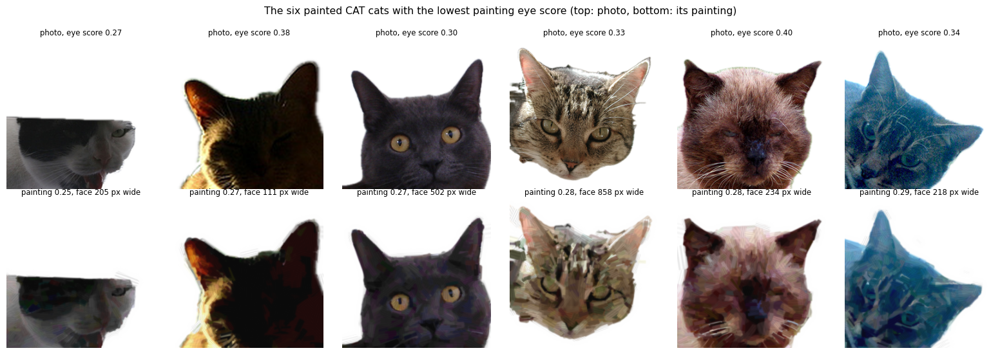

face width in the original photo (px), median / 5th percentile of all painted: 214.0 84.0
the six lowest: painting score [0.25, 0.27, 0.27, 0.28, 0.28, 0.29]  photo score [0.27, 0.38, 0.3, 0.33, 0.4, 0.34]  face width [205, 111, 502, 858, 234, 218]


(0.493, 0.496, 0.038, [0.37, 0.63])

In [24]:
# the cats whose paintings the judge likes least: a gallery that shows what a threshold would have to remove
worst = sorted(ok, key=lambda r: r["eye_conf"])[:6]
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for j, r in enumerate(worst):
    s_ = stem_of(r["id"])
    zz = np.load(cat_dir / f"{s_}.npz")
    bx = tuple(int(v) for v in zz["box"])
    ph = B.load(str(need(ML / "data/raw/cat_dataset/photos" / f"{s_}.jpg")), str(need(ML / "data/raw/cat_dataset/masks" / f"{s_}_mask1.png")), bx).target.numpy()
    ax[0, j].imshow(ph)
    ax[1, j].imshow(T.render(T.load_npz(str(cat_dir / f"{s_}.npz"))).clip(0, 1))
    ax[0, j].set_title(f"photo, eye score {r['eye_conf_photo']:.2f}", fontsize=8)
    ax[1, j].set_title(f"painting {r['eye_conf']:.2f}, face {r['side']} px wide", fontsize=8)
    ax[0, j].axis("off")
    ax[1, j].axis("off")
plt.suptitle("The six painted CAT cats with the lowest painting eye score (top: photo, bottom: its painting)", y=1.0)
plt.tight_layout()
plt.show()
print("face width in the original photo (px), median / 5th percentile of all painted:", np.median([r["side"] for r in C]), round(float(np.quantile([r["side"] for r in C], 0.05)), 1))
print("the six lowest: painting score", [round(r["eye_conf"], 2) for r in worst], " photo score", [round(r["eye_conf_photo"], 2) for r in worst], " face width", [r["side"] for r in worst])
ver("CAT: median painting eye score / photo eye score / eye_err; 5th-95th pct of painting score", (round(float(np.median(conf)), 3), round(float(np.median(phot)), 3), round(float(np.median(err)), 3), [round(float(q), 2) for q in np.quantile(conf, [0.05, 0.95])]), "cat_brush_face/log.jsonl", "computed here")

### 7.1 What this shows, and what is still unknown

**Progress.** The CAT dataset is painted: 6,983 paintings for the training list of 7,065 cats (the exact count and time are printed
above). The rest were not painted: 49 cats whose subject mask misses an eye (skipped before painting) and 33 that have no subject mask at all.
The Mac painted 4,793 and Colab 2,191 (from the log).

**Eye quality of the paintings.** Painting reproduces what the photo shows: the median eye score of a painting (0.493) is 99.5% of its photo's
(0.496), and the typical eye found by the judge lies 0.038 eye distances from the hand-labelled one (95th percentile 0.104). The spread is wide,
though (5th to 95th percentile of the painting's eye score: 0.37 to 0.63). The gallery shows the lowest scores. In five of the six the *photo*
scores low too (0.27 to 0.38), so these are not failed paintings: a head cut by the frame, a cat in deep shade, a head turned to the side, and
two cats (a dark grey one and a tabby) whose eyes are clearly visible yet score low on the photo, a blind spot of the judge itself. The fifth is
different: a cat with half-closed eyes whose photo scores 0.40 and whose painting only 0.28, so the painting lost the eyes the photo had. Face size
is not the cause (the six faces are 111 to 858 px wide).

**The threshold (set 2026-10-16).** A threshold on the painting's own eye score would remove the hard photos along with the bad paintings, so the
rule compares the painting with its photo: a cat is left out when the judge's eye score on the painting is below 0.85 of that on the photo, or
when the judge finds the painting's eyes more than 0.2 eye distances from the hand-labelled ones. It leaves out 135 of the 6,965 cats with eye
measures (1.9%, numbers printed above), the fifth cat of the gallery among them. With this rule, run J's data (`tokens_J.npz`) has 10,933
paintings: 3,413 + 6,327 training cats (AFHQ + CAT), 292 + 521 validation, 380 AFHQ test.

**No model has been trained on these paintings yet.** Run J (run I's flags on the combined data) is prepared but not finished, so this notebook
makes **no claim** that more cats improve the eyes (idea P3). The baseline to beat is fixed and reproducible: eye ratio D 0.84, H 0.89, I 0.91
on the same judge, FID 209, 194, 182 on AFHQ's own validation cats. J will be measured the same way on the AFHQ validation and test cats (its
AFHQ cats have exactly I's strokes; the stroke order is worked out again after alignment, because the CAT dataset has
upside-down and sideways cats), with the CAT validation cats reported separately.

### 7.2 Run J: how big the model is, and how many paintings it learns from

Run J is the next model: run I's recipe (aligned faces, face points first, eye-region loss × 3) trained on the AFHQ and CAT
paintings together, so the planned difference from I is the data. One more change comes with the data: the stroke order
inside each stage is worked out again after the faces are aligned, because the CAT dataset has upside-down and sideways
cats (`docs/model-versions.md`, run J). J is training on the Mac while this notebook is written; the next cell reads its
files when the notebook runs, so its last lines show how far it has got.

**The model: 27,894,784 parameters, the same network as run I.** Over half (54%) are in the feed-forward layers and
about a quarter (26%) in attention; the token table (7,499 tokens × 512 numbers) is also the output layer, so it is counted once. The
position table has a row for each of the 3,064 positions of a painting.

**The data: 10,933 paintings** (table below): 9,740 training cats (3,413 AFHQ + 6,327 CAT), 813 validation cats
(292 + 521) and AFHQ's 380 test cats. Every training cat is also used mirrored, so a pass over the data is 19,480
rows, 2.85 times run I's 6,826; each row is 3,064 tokens, i.e. 3,063 next-token predictions. A training step takes 16
rows, as in run I (I: 8 rows × 2 accumulation steps on an A100; J: 1 × 16 on the Mac, whose GPU memory cannot hold 8
rows of 3,064 tokens), at most 8,000 steps, with the validation loss measured every 100 steps.

In [25]:
from sellanything_ml.llm.model import GPT

jdir = RUNS / "J_cat_aligned_points_eyes"
jc = json.loads(need(jdir / "config.json").read_text())
ic = json.loads(need(RUNS / "I_aligned_points_eyes" / "config.json").read_text())
jm = GPT(G.model_config(G.Config(**jc["config"])))
parts = Counter()
for n_, p_ in jm.named_parameters():
    parts["token table (also the output layer)" if n_.startswith("embed") else "position table" if n_.startswith("pos")
          else "attention, 7 layers" if ".attn." in n_ else "feed-forward, 7 layers" if ".mlp." in n_ else "normalisation"] += p_.numel()
total = sum(parts.values())
display(pd.DataFrame([{"part": k, "parameters": v, "share": f"{v / total:.1%}"} for k, v in parts.items()]).set_index("part"))
print(f"parameters: {total:,} (J's config.json: {jc['parameters']:,}; run I: {ic['parameters']:,})")
display(pd.DataFrame(jt).T.assign(total=lambda d: d.sum(1)))
rows_per_step = jc["config"]["batch"] * jc["config"]["accum"]
per_pass = jc["train_rows"] / rows_per_step
print(f"training rows (cats and their mirror images): {jc['train_rows']:,} = {jc['train_rows'] / ic['train_rows']:.2f} x run I's {ic['train_rows']:,}")
print(f"tokens a row: {G.SEQ + G.PREFIX:,};  predicted tokens in one pass: {jc['train_rows'] * (G.SEQ + G.PREFIX - 1):,}")
print(f"rows a step: {rows_per_step} (J batch {jc['config']['batch']} x {jc['config']['accum']}; I {ic['config']['batch']} x {ic['config']['accum']}); "
      f"steps a pass: {per_pass:,.1f}; at most {jc['config']['max_steps']:,} steps = {jc['config']['max_steps'] / per_pass:.2f} passes")
jm_ = jl(jdir / "metrics.jsonl") if (jdir / "metrics.jsonl").exists() else []
if jm_:
    r_ = jm_[-1]
    print(f"progress when this notebook ran ({now}): step {r_['step']:,}, {r_['epoch']} passes, validation loss {r_['val_loss']}, "
          f"{r_['seconds']} s a step on the Mac's GPU")
else:
    print("progress when this notebook ran: no evaluation yet")
ver("run J: parameters / training cats / training rows / validation cats", (total, jc["train_cats"], jc["train_rows"], jc["val_rows"]),
    "runs/brushgpt/J_cat_aligned_points_eyes/config.json; brushgpt.model_config", "computed here")

,parameters,share
part,,
token table (also the output layer),3839488,13.8%
position table,1568768,5.6%
normalisation,7680,0.0%
"attention, 7 layers",7340032,26.3%
"feed-forward, 7 layers",15138816,54.3%


parameters: 27,894,784 (J's config.json: 27,894,784; run I: 27,894,784)


,AFHQ,CAT,total
train,3413,6327,9740
val,292,521,813
test,380,0,380


training rows (cats and their mirror images): 19,480 = 2.85 x run I's 6,826
tokens a row: 3,064;  predicted tokens in one pass: 59,667,240
rows a step: 16 (J batch 1 x 16; I 8 x 2); steps a pass: 1,217.5; at most 8,000 steps = 6.57 passes
progress when this notebook ran (2026-10-16 20:25): step 1,300, 1.07 passes, validation loss 3.9666, 13.76 s a step on the Mac's GPU


(27894784, 9740, 19480, 813)

### 7.3 State of the paper-derived ideas (as of 2026-10-14, from `docs/test-checklist.md`; P3 updated 2026-10-16)

| idea | what | status |
|---|---|---|
| P1 | absolute coordinates + alignment | **done**: eye ratio D 0.84 → H 0.89 (section 5) |
| P2 | colour tokens as a K-means dictionary | **measured, not done**: 3,156 of 6,912 colour tokens never used. It had been set aside because the errors seemed to be in the coarse and middle strokes; section 6.3 now places them mostly in the finest stages, so the reason no longer holds and P2 is open again |
| P3 | paint more cats from the same distribution (CAT dataset) | **painted** (2026-10-16); run J prepared, not yet trained, so no "did it help" result |
| P4 | pre-train on painted dogs and wild animals, then fine-tune on cats | **not started**; no evidence it would fix eyes; costly (more painting) |
| P5 | face points as a condition with classifier-free guidance | **not started**; `brushgpt.py` has no unconditional token or guidance; no direct evidence for eyes; needs one more training |
| P6 | give the model the real first k stages, let it paint the rest (R1's Level task) | **measured for run I** (2026-10-16, section 6.3): the eyes are lost mostly in the two finest stages; run J is measured when it finishes |

## 8. Limitations and next steps

**Limitations (all stated by the evidence above).**

1. **One training per configuration.** Every run in section 5 is a single run with seed 0. Differences in validation loss of a few hundredths, and
   eye-score differences of about 0.01 to 0.02, are within what noise could produce; only the D to G/H/I steps exceed three standard errors.
2. **The effect of the per-field output layers (section 4) was never isolated** from the overlap order and the larger dataset, and by construction
   it forces decodability, so "256/256 decodable" is not a quality result.
3. **The eye judge is a proxy**, built on a model whose own confidence does not predict its errors (AUROC 0.57); we use it only to compare paintings
   against paintings of the same kind. No human rating of the eyes was recorded, and no AFHQ hand-label transfer score exists.
4. **FID here is a relative number** (256 generated paintings against the run's own training renders, with 39.5 to 41.8 for real validation paintings as the floor),
   not comparable with published FIDs and not available for run C.
5. **Not measured:** run-to-run variance; the hand-label transfer of the landmark model to AFHQ; the
   Kaggle trial's own logs; the single effect of overlap order.
6. **Small data.** 3,413 training cats (6,826 with mirrors); the model overfits after about 6 to 8 epochs. The samples are cat-like painted faces; they are not
   photographic, and the colour field (6,912 tokens) is the part of each stroke the model knows least about.

**Next steps.** (a) Done 2026-10-16: the CAT dataset is painted and the eye-quality threshold is set (section 7.1); the lowest-scoring cats are shown above.
(b) Train on AFHQ plus CAT with the run-I settings, and measure exactly as in section 5 on the AFHQ validation cats. (c) Only then decide between P4 and P5.
(d) If a time-and-money budget allows, repeat run I with two more seeds to put a number on run-to-run variance.

## 9. Verification: where every number comes from

The table lists every number this notebook registered while it ran, with its source file and one of three kinds:
**computed here** (computed by the cells above from the file shown), **quoted** (copied from the named project document;
the raw output behind it was not kept as a file), **not measured**. The next cell checks that every file the notebook read exists and that the
frozen weights and token files have the hashes recorded in `docs/model-versions.md`.

In [26]:
def fmt(v):
    return str(v).replace("|", "/")


lines = ["| # | number | value | source | kind |", "|---|---|---|---|---|"]
for i, (claim, value, source, kind) in enumerate(VERIFY, 1):
    lines.append(f"| {i} | {fmt(claim)} | {fmt(value)} | {fmt(source)} | {kind} |")
display(Markdown("\n".join(lines)))
print(Counter(k for *_, k in VERIFY))

| # | number | value | source | kind |
|---|---|---|---|---|
| 1 | shelter painter, run I on the CPU: seconds per cat (mean) / cats | (13.9, 8) | _src/data_08/shelter_run_I.npz (make_08_shelter.py) | computed here |
| 2 | shelter run (8 cats, run I, CPU, seed 0): eye score mean +- SE | (0.4828, 0.0214) | _src/data_08/shelter_eye.json (make_08_shelter_eye.py) | computed here |
| 3 | landmark model pose_scratch: test NME / failure rate (NME>0.1) | (0.078, 0.214) | cat-face-landmarks/runs/pose_scratch/eval_test.json | computed here |
| 4 | landmark model pose_mae: test NME / failure rate (NME>0.1) | (0.067, 0.122) | cat-face-landmarks/runs/pose_mae/eval_test.json | computed here |
| 5 | MAE held-out loss, epoch 1 -> 300 | (1.2407, 0.4723) | cat-face-landmarks/runs/mae/metrics.jsonl | computed here |
| 6 | AFHQ cats labelled (MAE, pad 1.5) | 5558 | ml/data/processed/afhq_cats_mae_pad1.5.npz | computed here |
| 7 | cats with an ear tip outside the image (>0 / >0.1 eye distances) | (0.365, 0.224) | ml/data/processed/afhq_cats_mae_pad1.5_checks.npz | computed here |
| 8 | rule A / rule B / both / kept (AFHQ, 5,558 cats) | (1245, 278, 50, 4085) | ml/data/processed/afhq_cats_mae_pad1.5_checks.npz (same formula as tools/paint_afhq.py) | computed here |
| 9 | paintings in tokens_runs_DEFG.npz, train / val / test | (3413, 292, 380) | ml/data/processed/brushgpt/tokens_runs_DEFG.npz | computed here |
| 10 | strokes per painting / tokens per painting | (608, 3046) | ml/sellanything_ml/sketch/catbrush.py STAGES, brushgpt.py SEQ | computed here |
| 11 | vocabulary size | 7499 | ml/sellanything_ml/sketch/brushtokens.py | computed here |
| 12 | tokens per painting with face points / predictions per painting | (3064, 3063) | ml/sellanything_ml/sketch/brushgpt.py SEQ, PREFIX | computed here |
| 13 | demo cat L1 to photo after stages 1-4 | [0.0611, 0.045, 0.035, 0.0282] | ml/data/processed/brushgpt/tokens_runs_DEFG.npz + AFHQ photo | computed here |
| 14 | mean L1 after stages 1-4 (20 validation cats) | [0.0642, 0.0471, 0.0359, 0.0287] | tokens_runs_DEFG.npz + AFHQ photos | computed here |
| 15 | token round trip exact (decode -> encode) | 205/205 | tokens_runs_DEFG.npz | computed here |
| 16 | logged painter L1 vs rebuilt-from-tokens L1, max abs difference | 5e-05 | afhq_brush_face/log.jsonl | computed here |
| 17 | L1 stages 1-3 / 1-4 / 1-5 (60 cats), tokens 1,245 / 3,046 / 6,047 | (0.0376, 0.0303, 0.0263) | docs/devlog/2026-10-10.md §4 | quoted |
| 18 | L1 after stage 5: continuous vs snapped to tokens (one cat) | (0.0229, 0.0256) | docs/devlog/2026-10-09.md (Brush strokes) | quoted |
| 19 | quantising one field at a time, L1 increase (position 2 px, colour 8 levels) | (0.0028, 0.0029) | docs/devlog/2026-10-09.md | quoted |
| 20 | stage 5 token cost / L1 gain | (3001, 0.004) | derived from the quoted table | computed here |
| 21 | jump between consecutive strokes, list -> overlap order, stage 4 (px) | (116.1, 29.9) | tokens_runs_DEFG.npz tokens vs tokens_overlap | computed here |
| 22 | max pixel change from re-ordering (6 cats) | 1.19e-07 | tokens_runs_DEFG.npz | computed here |
| 23 | seconds per cat, AFHQ, Mac: median / mean | (35.0, 44.6) | afhq_brush_face/log.jsonl | computed here |
| 24 | seconds per cat, AFHQ, Modal L4: median / mean | (11.6, 12.4) | afhq_brush_face/log_modal.jsonl | computed here |
| 25 | seconds per cat, CAT, Mac: median / mean | (33.0, 45.4) | cat_brush_face/log.jsonl | computed here |
| 26 | seconds per cat, CAT, Colab: median / mean | (15.9, 16.8) | cat_brush_face/log.jsonl | computed here |
| 27 | trial: decodable samples of 256, tokens in right field (809 cats) | (0, 0.845) | docs/devlog/2026-10-11.md §2 | quoted |
| 28 | run D: eye-stroke loss | 4.036 | docs/model-versions.md (Brush GPT table) | quoted |
| 29 | run C: best validation loss (step) | (4.0417, 1600) | runs/brushgpt/C_overlap_heads/metrics.jsonl | computed here |
| 30 | run D: best validation loss (step) | (3.9331, 2900) | runs/brushgpt/D_all_cats/metrics.jsonl | computed here |
| 31 | run D: FID of 256 samples vs training renders | 209.4 | runs/brushgpt/D_all_cats/eval.json | computed here |
| 32 | run D: eye judge real / generated (SE) | (0.501, 0.42, 0.007) | docs/devlog/2026-10-12.md §1, §5 and docs/model-versions.md | quoted |
| 33 | run E: best validation loss (step) | (3.9166, 2900) | runs/brushgpt/E_points/metrics.jsonl | computed here |
| 34 | run E: FID of 256 samples vs training renders | 208.6 | runs/brushgpt/E_points/eval.json | computed here |
| 35 | run E: eye judge real / generated (SE) | (0.501, 0.438, 0.007) | docs/devlog/2026-10-12.md §1, §5 and docs/model-versions.md | quoted |
| 36 | run F: best validation loss (step) | (3.9609, 2900) | runs/brushgpt/F_eye_weight/metrics.jsonl | computed here |
| 37 | run F: FID of 256 samples vs training renders | 232.5 | runs/brushgpt/F_eye_weight/eval.json | computed here |
| 38 | run F: eye judge real / generated (SE) | (0.501, 0.434, 0.006) | docs/devlog/2026-10-12.md §1, §5 and docs/model-versions.md | quoted |
| 39 | run G: best validation loss (step) | (3.9471, 3400) | runs/brushgpt/G_points_eyes/metrics.jsonl | computed here |
| 40 | run G: FID of 256 samples vs training renders | 228.5 | runs/brushgpt/G_points_eyes/eval.json | computed here |
| 41 | run G: eye judge real / generated (SE) | (0.501, 0.451, 0.006) | docs/devlog/2026-10-12.md §1, §5 and docs/model-versions.md | quoted |
| 42 | run H: best validation loss (step) | (3.886, 2900) | runs/brushgpt/H_aligned/metrics.jsonl | computed here |
| 43 | run H: FID of 256 samples vs training renders | 193.6 | runs/brushgpt/H_aligned/eval.json | computed here |
| 44 | run H: eye judge real / generated (SE) | (0.537, 0.479, 0.006) | docs/devlog/2026-10-12.md §1, §5 and docs/model-versions.md | quoted |
| 45 | run I: best validation loss (step) | (3.9152, 2500) | runs/brushgpt/I_aligned_points_eyes/metrics.jsonl | computed here |
| 46 | run I: FID of 256 samples vs training renders | 182.5 | runs/brushgpt/I_aligned_points_eyes/eval.json | computed here |
| 47 | run I: eye judge real / generated (SE) | (0.537, 0.488, 0.006) | docs/devlog/2026-10-12.md §1, §5 and docs/model-versions.md | quoted |
| 48 | run C FID | not measured (the evaluation crashed in the FID step) | runs/brushgpt/C_overlap_heads/eval.log | not measured |
| 49 | run D per-field validation loss x / y / angle / size / paint | [4.607, 4.04, 3.156, 3.196, 4.698] | runs/brushgpt/D_all_cats/metrics.jsonl | computed here |
| 50 | FID of real validation paintings vs training renders (D-G / H-I) | (39.5, 41.8) | runs/brushgpt/D_all_cats/eval.json, H_aligned/eval.json | computed here |
| 51 | eye judge, real unaligned validation paintings (128): mean +- SE | (0.5006, 0.007) | _src/data_08/eye_real.json (make_08_assets.py); devlog says 0.501 | computed here |
| 52 | eye judge, real aligned validation paintings (128): mean +- SE | (0.5371, 0.0039) | _src/data_08/eye_real.json; devlog says 0.537 | computed here |
| 53 | real aligned paintings, eye score after stage 1/2/3/4 (64 cats) | [0.429, 0.495, 0.526, 0.537] | _src/data_08/eye_real.json; devlog 0.429/0.495/0.527/0.537 | computed here |
| 54 | run H finished 0.479; run I finished 0.488 (generated, 128 samples) | (0.479, 0.488) | docs/devlog/2026-10-12.md §1, §5 | quoted |
| 55 | run I stage continuation: eye score with real first k = 0..3 stages + model (64 cats) | [0.4889, 0.5135, 0.4998, 0.5178] | runs/brushgpt/I_aligned_points_eyes/stage_continuation_afhq_t1.0.json | computed here |
| 56 | run I: what its stages 3-4 add (given real 1-2) vs what the real ones add | (0.0046, 0.0417) | runs/brushgpt/I_aligned_points_eyes/stage_continuation_afhq_t1.0.npz (paired) | computed here |
| 57 | run I teacher-forced loss of stages 1..4 | [4.1513, 4.166, 3.941, 3.8024] | runs/brushgpt/I_aligned_points_eyes/stage_continuation_afhq_t1.0.json | computed here |
| 58 | run J stage continuation | not measured | J is still training; tools/run_stage_continuation_J.sh runs it when J finishes | not measured |
| 59 | CAT cats with no subject mask | 33 | ml/data/raw/cat_dataset/masks | computed here |
| 60 | CAT paintings (.npz) at execution time | (6983, '2026-10-16 20:25') | ml/data/processed/cat_brush_face/*.npz | computed here |
| 61 | CAT training list size / Mac share / Colab job | (7065, 4065, 2973) | catface/train.npz; run_mac_paint.sh; colab_paint/pkg/job.json | computed here |
| 62 | CAT cats skipped (eyes outside the subject mask) | 49 | cat_brush_face/log.jsonl | computed here |
| 63 | CAT cats left out by the eye rule (low ratio / far / both / all) | (73, 73, 11, 135) | cat_brush_face/log.jsonl; brushgpt.CAT_EYE_* | computed here |
| 64 | run J data: train AFHQ + CAT, val AFHQ + CAT, test AFHQ | (3413, 6327, 292, 521, 380) | ml/data/processed/brushgpt/tokens_J.npz | computed here |
| 65 | CAT: median painting eye score / photo eye score / eye_err; 5th-95th pct of painting score | (0.493, 0.496, 0.038, [0.37, 0.63]) | cat_brush_face/log.jsonl | computed here |
| 66 | run J: parameters / training cats / training rows / validation cats | (27894784, 9740, 19480, 813) | runs/brushgpt/J_cat_aligned_points_eyes/config.json; brushgpt.model_config | computed here |

Counter({'computed here': 52, 'quoted': 12, 'not measured': 2})


In [27]:
# every file read exists; every document cited exists; frozen files carry the hashes of docs/model-versions.md
cited = ["docs/devlog/2026-10-09.md", "docs/devlog/2026-10-10.md", "docs/devlog/2026-10-11.md", "docs/devlog/2026-10-12.md",
         "docs/model-versions.md", "docs/paper-ideas.md", "docs/test-checklist.md",
         "ml/sellanything_ml/sketch/catbrush.py", "ml/sellanything_ml/sketch/brushtokens.py", "ml/sellanything_ml/sketch/brushgpt.py",
         "ml/tools/paint_afhq.py", "ml/tools/paint_cat_dataset.py", "ml/tools/eye_judge.py", "ml/tools/modal_brushgpt.py",
         "ml/tools/run_mac_paint.sh", "ml/tools/prepare_colab_paint.py", "ml/tools/merge_colab_paint.py"]
REPO = ML.parent
missing = [str(p) for p in USED if not Path(p).exists()] + [c for c in cited if not (REPO / c).exists()]
print(f"{len(set(map(str, USED)))} files read by cells, {len(cited)} documents/code files cited; missing: {missing or 'none'}")
assert not missing

expected = {"runs/brushgpt/C_overlap_heads/best.pt": "674f4821ad20572d", "runs/brushgpt/D_all_cats/best.pt": "c42c6aa9f2cd4761",
            "runs/brushgpt/E_points/best.pt": "542e57c7607a31dd", "runs/brushgpt/F_eye_weight/best.pt": "4120cf923fdff45b",
            "runs/brushgpt/G_points_eyes/best.pt": "59dd0aeb357b387b", "runs/brushgpt/H_aligned/best.pt": "5eef3372f296172b",
            "runs/brushgpt/I_aligned_points_eyes/best.pt": "6f783ff675b632a3",
            "data/processed/brushgpt/tokens_trial_1792.npz": "00457d1caaf486d7", "data/processed/brushgpt/tokens_run_D.npz": "eef2c0ecdb6cdaf3",
            "data/processed/brushgpt/tokens_runs_DEFG.npz": "61ea76e9ca4d8ce6", "data/processed/brushgpt/tokens_runs_HI.npz": "45486e9dc86ed364"}
rows = []
for rel, want in expected.items():
    got = hashlib.sha256((ML / rel).read_bytes()).hexdigest()[:16]
    rows.append({"file": rel, "sha256 (first 16)": got, "docs/model-versions.md": want, "match": got == want})
display(pd.DataFrame(rows).set_index("file"))
assert all(r["match"] for r in rows)

66 files read by cells, 17 documents/code files cited; missing: none


,sha256 (first 16),docs/model-versions.md,match
file,,,
runs/brushgpt/C_overlap_heads/best.pt,674f4821ad20572d,674f4821ad20572d,True
runs/brushgpt/D_all_cats/best.pt,c42c6aa9f2cd4761,c42c6aa9f2cd4761,True
runs/brushgpt/E_points/best.pt,542e57c7607a31dd,542e57c7607a31dd,True
runs/brushgpt/F_eye_weight/best.pt,4120cf923fdff45b,4120cf923fdff45b,True
runs/brushgpt/G_points_eyes/best.pt,59dd0aeb357b387b,59dd0aeb357b387b,True
runs/brushgpt/H_aligned/best.pt,5eef3372f296172b,5eef3372f296172b,True
runs/brushgpt/I_aligned_points_eyes/best.pt,6f783ff675b632a3,6f783ff675b632a3,True
data/processed/brushgpt/tokens_trial_1792.npz,00457d1caaf486d7,00457d1caaf486d7,True
data/processed/brushgpt/tokens_run_D.npz,eef2c0ecdb6cdaf3,eef2c0ecdb6cdaf3,True


All files exist and the frozen weights and token files have the recorded hashes, so every run in section 5 can be traced to its data and weights.

**Written as "not measured" in this notebook:** the Kaggle trial's own logs and samples (only the devlog's numbers exist); the effect of the per-field
output layers alone (and of the overlap order alone); FID of run C; run-to-run variance of any configuration; the landmark model's
hand-label transfer to AFHQ; and any result of training on the CAT dataset's paintings (none has been trained).